# Task 1 — Data Preparation and Exploration

Neste notebook é realizada a **exploração, análise e preparação dos dados** do dataset `Charging_Data_educational.csv`.

As etapas incluem:
- carregamento do dataset;
- exploração inicial dos dados;
- análise de valores em falta;
- tratamento dos valores em falta;
- normalização dos nomes das variáveis;
- deteção de duplicados e valores inválidos;
- conversão das variáveis temporais;
- validação de relações temporais;
- análise das variáveis categóricas e da tarifa de eletricidade.


In [1]:
import pandas as pd
from tabulate import tabulate
import re
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 1. Carregamento e visualização inicial

O dataset `Charging_Data_educational.csv` é carregado para um `DataFrame` do pandas.

De seguida, são apresentadas as primeiras e as últimas 10 observações do dataset para permitir uma primeira análise da sua estrutura e dos valores existentes.


In [2]:
# Ler o CSV
df = pd.read_csv("Charging_Data_educational.csv")


# Mostrar o DataFrame como tabela
print(
    f"""
    Head Dataset

    {tabulate(
        df.head(10),
        headers="keys",
        tablefmt="grid",
        showindex=False
    )}
    """
)

print(f"""
Tail Dataset

{tabulate(
    df.tail(10),
    headers="keys",
    tablefmt="grid",
    showindex=False
)}
""")


    Head Dataset

    +----------+--------------------+-------------------------------+-----------------+-----------------------+-------------------------+-------------------------+-----------------------+---------------------------+-----------------------+---------------------+---------------------+---------------------+------------------+------------------------+---------------------+------------------------+---------------------+-----------------+-----------------------------+-----------------------------+----------------------------------+-----------------------------+-----------------------------+----------------------------------+------------------------------+------------------------------+-----------------------------------+-----------------------------------------------+--------------------------------------+------------------------------------------------+---------------------------------------+---------------+------------------------------+------------------------------+---

## 3. Informação geral do DataFrame

Obter informação geral sobre o DataFrame, incluindo:
- número de linhas;
- número de colunas;
- nomes das variáveis;
- tipos de dados;
- quantidade de valores não nulos.


In [3]:
#3.Get all information about the dataframe, such as the number of rows, number of columns, column names and their types.
print("-- info --")
print(df.info())
print("\n")

-- info --
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 441077 entries, 0 to 441076
Data columns (total 47 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   UserID                                        441077 non-null  int64  
 1   Charging Post ID                              441077 non-null  int64  
 2   Location Information                          441077 non-null  object 
 3   District Name                                 441077 non-null  object 
 4   Order creation time                           441077 non-null  object 
 5   Transaction power/kwh                         441077 non-null  float64
 6   Electricity cost/Yuan                         441077 non-null  float64
 7   Service charge/Yuan                           441077 non-null  float64
 8   Transaction Amount/Yuan                       441077 non-null  float64
 9   Actual Payment/Yuan                  

## 4. Nomes das variáveis

Visualizar apenas os nomes das variáveis existentes no DataFrame.


In [4]:
#4. View only the variable names in this dataframe.
print("-- variable names --")
print(df.columns)
print("\n")

-- variable names --
Index(['UserID', 'Charging Post ID', 'Location Information', 'District Name',
       'Order creation time', 'Transaction power/kwh', 'Electricity cost/Yuan',
       'Service charge/Yuan', 'Transaction Amount/Yuan', 'Actual Payment/Yuan',
       'Start Time', 'End Time', 'Payment time', 'Temperature(℃)',
       'Relative Humidity(%)', 'Precipitation(mm)', 'end_cause',
       'electricity_price', 'tariff_period', 'post_previous_sessions_1D',
       'post_previous_abnormal_1D', 'post_previous_abnormal_rate_1D',
       'post_previous_sessions_7D', 'post_previous_abnormal_7D',
       'post_previous_abnormal_rate_7D', 'post_previous_sessions_30D',
       'post_previous_abnormal_30D', 'post_previous_abnormal_rate_30D',
       'post_hours_since_previous_completed_session',
       'post_no_previous_completed_session',
       'post_hours_since_previous_completed_abnormal',
       'post_no_previous_completed_abnormal', 'is_new_user',
       'user_previous_sessions_30D', 'user

## 5. Dimensão do dataset

Determinar o tamanho do conjunto de dados.

São apresentados:
- `shape`: número de linhas e número de colunas;
- `size`: número total de elementos do DataFrame.


In [5]:
#5. What is the size of the data set?

print(f"Shape : {df.shape}")
print(f"Size : {df.size}")
print("\n")

Shape : (441077, 47)
Size : 20730619




## 6. Estatísticas das variáveis numéricas

Obter estatísticas descritivas das variáveis numéricas do dataset, permitindo analisar medidas como:
- contagem;
- média;
- desvio padrão;
- mínimo;
- quartis;
- máximo.


In [6]:
#6. Get statistics from the dataframe's numerical columns and frequency tables for categorical variables.
print(f"Describe \n: {df.describe()}")
print("\n")

Describe 
:               UserID  Charging Post ID  Transaction power/kwh  \
count  441077.000000     441077.000000          441077.000000   
mean    13262.864430         48.829583              16.436574   
std     14286.825468         25.045206              13.253881   
min         1.000000          1.000000               0.000000   
25%      2478.000000         26.000000               5.440000   
50%      8819.000000         51.000000              15.150000   
75%     19614.000000         69.000000              24.740000   
max     56117.000000         92.000000             117.740000   

       Electricity cost/Yuan  Service charge/Yuan  Transaction Amount/Yuan  \
count          441077.000000        441077.000000            441077.000000   
mean               12.158460             7.450791                19.609251   
std                10.830214             8.152830                15.958935   
min                 0.000000             0.000000                 0.000000   
25%         

## 7. Variáveis de texto

Obter os valores das variáveis de texto (`object`) existentes no DataFrame.


In [7]:
#7.Get values from the dataframe's text columns.
print(f"""Describe \n: {df.select_dtypes(include="object")}""")
print("\n")

Describe 
:        Location Information District Name    Order creation time  \
0             Shopping Mall     Tongxiang  2019-12-31 21:26:58\t   
1         Government Agency       Xiuzhou  2019-12-31 21:50:58\t   
2                    Park B     Tongxiang  2019-12-31 22:19:34\t   
3             Shopping Mall     Tongxiang  2019-12-31 22:37:24\t   
4               Bus Station     Tongxiang  2019-12-31 23:32:28\t   
...                     ...           ...                    ...   
441072    Industrial Park\t     Tongxiang  2021-12-31 23:40:47\t   
441073     Wholesale Market       Xiuzhou  2021-12-31 23:40:24\t   
441074          Bus Station     Tongxiang  2021-12-31 23:46:55\t   
441075   Tourist Attraction         Nanhu  2021-12-31 23:48:11\t   
441076    Industrial Park\t     Tongxiang  2021-12-31 23:54:12\t   

                 Start Time             End Time           Payment time  \
0       2019-12-31 21:27:03  2020-01-01 05:03:53  2020-01-01 05:03:40\t   
1       2019-12-31 21

## 8. Análise de valores em falta

Verificar a quantidade de valores `NaN` existente em cada variável do DataFrame.

É também indicado o número inicial de linhas do dataset.


In [8]:
#8.Check null values from columns dataframe.
print("-- Count number of Nas per column. --")
print(df.isna().sum())
print(f"Initial rows: {len(df)}")
print("\n")


-- Count number of Nas per column. --
UserID                                               0
Charging Post ID                                     0
Location Information                                 0
District Name                                        0
Order creation time                                  0
Transaction power/kwh                                0
Electricity cost/Yuan                                0
Service charge/Yuan                                  0
Transaction Amount/Yuan                              0
Actual Payment/Yuan                                  0
Start Time                                           0
End Time                                             0
Payment time                                         0
Temperature(℃)                                       0
Relative Humidity(%)                                 0
Precipitation(mm)                                    0
end_cause                                            0
electricity_price          

## 9. Remoção de linhas completamente vazias

Identificar e remover as linhas em que **todas as colunas apresentam valores `NaN`**.

Depois da remoção, é apresentada a quantidade de linhas restantes e a quantidade de valores em falta por coluna.


In [9]:
#9. Remove the line with all columns: NaN.
print("-- Remove rows where all columns are NaN --")

df.dropna(how="all", inplace=True)

print(f"Remaining rows: {len(df)}")
print(f"Rows with all NaN: {df.isna().all(axis=1).sum()}")

print("\nMissing values per column:")
print(df.isna().sum())


-- Remove rows where all columns are NaN --
Remaining rows: 441077
Rows with all NaN: 0

Missing values per column:
UserID                                               0
Charging Post ID                                     0
Location Information                                 0
District Name                                        0
Order creation time                                  0
Transaction power/kwh                                0
Electricity cost/Yuan                                0
Service charge/Yuan                                  0
Transaction Amount/Yuan                              0
Actual Payment/Yuan                                  0
Start Time                                           0
End Time                                             0
Payment time                                         0
Temperature(℃)                                       0
Relative Humidity(%)                                 0
Precipitation(mm)                                    0
end_

## 10. Variáveis com valores em falta

Identificar as colunas que ainda apresentam valores `NaN` e calcular:
- número de valores em falta;
- percentagem de valores em falta relativamente ao total de observações.

Esta análise permite perceber quais as variáveis que necessitam de tratamento adicional.


In [10]:

# 10. Check columns with many null values

print("-- Columns with null values --")

nulls = df.isna().sum()
null_percentage = (df.isna().mean() * 100)

null_summary = pd.DataFrame({
    "Null_Count": nulls,
    "Null_Percentage": null_percentage
})

# Mostrar apenas colunas que têm valores nulos
null_summary = null_summary[null_summary["Null_Count"] > 0]

print(
    tabulate(
        null_summary,
        headers="keys",
        tablefmt="grid"
    )
)


#verificar qual o motivo pelo qual tem valores null e atribuir uma label para cada uma das situações (-1)

-- Columns with null values --
+----------------------------------------------+--------------+-------------------+
|                                              |   Null_Count |   Null_Percentage |
+==============================================+==============+===================+
| post_hours_since_previous_completed_session  |           92 |         0.020858  |
+----------------------------------------------+--------------+-------------------+
| post_hours_since_previous_completed_abnormal |          367 |         0.0832054 |
+----------------------------------------------+--------------+-------------------+
| user_days_since_previous_completed_session   |        56647 |        12.8429    |
+----------------------------------------------+--------------+-------------------+
| user_days_since_previous_completed_abnormal  |       136279 |        30.8969    |
+----------------------------------------------+--------------+-------------------+


### Investigação dos valores em falta nas variáveis históricas

Algumas variáveis históricas apresentam valores em falta (`NaN`). Antes de decidir como tratar estes valores, é necessário perceber **por que razão estão em falta**.

Por exemplo, a variável `user_days_since_previous_completed_session` indica quantos dias passaram desde a sessão anterior concluída pelo utilizador. No entanto, se o utilizador nunca teve uma sessão concluída anteriormente, não existe uma sessão anterior a partir da qual seja possível calcular esse valor. Neste caso, o valor em falta pode ser esperado e não representar um erro nos dados.

O dataset contém também variáveis indicadoras que informam se existe ou não histórico anterior, como `user_no_previous_completed_session`.

Assim, cada variável de tempo histórico é comparada com o respetivo indicador de ausência de histórico. O objetivo é responder à seguinte questão:

**Quando uma variável de tempo histórico está em falta, o indicador correspondente confirma que não existe histórico anterior?**

Se esta relação se verificar para todos os valores em falta, podemos concluir que estes valores têm um significado específico e não resultam de um problema de qualidade dos dados.

### Verificação da ausência de histórico

Para cada variável que representa o tempo desde uma sessão anterior, é comparada a existência de valores em falta com a respetiva variável indicadora `no_previous`.

O objetivo é verificar se os `NaN` ocorrem precisamente quando não existe histórico anterior.


In [11]:
# Pair each historical time variable with its corresponding indicator
missing_history_pairs = {
    "post_hours_since_previous_completed_session":
        "post_no_previous_completed_session",

    "post_hours_since_previous_completed_abnormal":
        "post_no_previous_completed_abnormal",

    "user_days_since_previous_completed_session":
        "user_no_previous_completed_session",

    "user_days_since_previous_completed_abnormal":
        "user_no_previous_completed_abnormal"
}

for time_col, flag_col in missing_history_pairs.items():

    print(f"\n--- {time_col} ---")

    print(pd.crosstab(
        df[flag_col],
        df[time_col].isna(),
        rownames=[flag_col],
        colnames=["Time is missing"],
        margins=True
    ))


--- post_hours_since_previous_completed_session ---
Time is missing                      False  True     All
post_no_previous_completed_session                      
0                                   440985     0  440985
1                                        0    92      92
All                                 440985    92  441077

--- post_hours_since_previous_completed_abnormal ---
Time is missing                       False  True     All
post_no_previous_completed_abnormal                      
0                                    440710     0  440710
1                                         0   367     367
All                                  440710   367  441077

--- user_days_since_previous_completed_session ---
Time is missing                      False   True     All
user_no_previous_completed_session                       
0                                   384430      0  384430
1                                        0  56647   56647
All                               

### Tratamento dos valores em falta nas variáveis históricas

A análise anterior mostrou que os valores em falta nas variáveis de tempo histórico ocorrem quando **não existe histórico anterior disponível**.

Por exemplo, quando `user_no_previous_completed_session = 1`, significa que não existe nenhuma sessão anterior concluída para esse utilizador. Por isso, não é possível calcular `user_days_since_previous_completed_session`, o que explica a existência do valor em falta.

Como estes `NaN` representam uma situação com significado e não um erro nos dados, é necessário atribuir-lhes uma representação numérica antes de utilizar estas variáveis na modelação.

Os valores em falta são substituídos por `-1`. Este valor é adequado porque um período de tempo decorrido não pode ser negativo. Assim:

- um valor positivo representa o tempo efetivamente decorrido desde a sessão anterior;
- `-1` representa a ausência de uma sessão anterior e, consequentemente, a impossibilidade de calcular o tempo decorrido.

As variáveis indicadoras `no_previous` são mantidas, uma vez que identificam explicitamente se existe ou não histórico anterior.

### Substituição dos valores em falta

Depois de confirmar que os valores em falta representam **ausência de histórico anterior**, estes valores são substituídos por `-1`.

As variáveis indicadoras `no_previous` são mantidas para preservar esta informação.


In [12]:
history_time_columns = [
    "post_hours_since_previous_completed_session",
    "post_hours_since_previous_completed_abnormal",
    "user_days_since_previous_completed_session",
    "user_days_since_previous_completed_abnormal"
]

df[history_time_columns] = df[history_time_columns].fillna(-1)

### Notas

A análise confirmou que os valores em falta nas quatro variáveis de tempo histórico não resultam de valores desconhecidos ou de erros de qualidade dos dados. Estes valores ocorrem porque **não existe uma sessão anterior concluída ou uma sessão anterior anormal** a partir da qual seja possível calcular o tempo decorrido.

Assim, os valores em falta foram considerados representativos da ausência de histórico, e não como problemas de qualidade dos dados.

Para preparar os dados para a modelação, os valores em falta foram substituídos por `-1`, representando a ausência de histórico anterior. As respetivas variáveis indicadoras `no_previous` foram mantidas para preservar explicitamente esta informação.

## 11. Normalização dos nomes das variáveis

Normalizar os nomes das colunas para obter uma nomenclatura consistente.

São aplicadas as seguintes transformações:
- remoção de espaços no início e no fim;
- conversão para letras minúsculas;
- substituição de caracteres especiais por `_`;
- remoção de `_` no início e no fim.


In [13]:
#11.Standardize columns names

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-zA-Z0-9]+", "_", regex=True)
    .str.strip("_")
)

print(df.columns)
print("\n")

Index(['userid', 'charging_post_id', 'location_information', 'district_name',
       'order_creation_time', 'transaction_power_kwh', 'electricity_cost_yuan',
       'service_charge_yuan', 'transaction_amount_yuan', 'actual_payment_yuan',
       'start_time', 'end_time', 'payment_time', 'temperature',
       'relative_humidity', 'precipitation_mm', 'end_cause',
       'electricity_price', 'tariff_period', 'post_previous_sessions_1d',
       'post_previous_abnormal_1d', 'post_previous_abnormal_rate_1d',
       'post_previous_sessions_7d', 'post_previous_abnormal_7d',
       'post_previous_abnormal_rate_7d', 'post_previous_sessions_30d',
       'post_previous_abnormal_30d', 'post_previous_abnormal_rate_30d',
       'post_hours_since_previous_completed_session',
       'post_no_previous_completed_session',
       'post_hours_since_previous_completed_abnormal',
       'post_no_previous_completed_abnormal', 'is_new_user',
       'user_previous_sessions_30d', 'user_previous_abnormal_30d',
   

## 12. Deteção de linhas duplicadas

Verificar o número de linhas duplicadas existentes no DataFrame antes de proceder a qualquer remoção.


In [14]:
#12.Número de linhas duplicadas
print(f"\nNúmero de linhas duplicadas (antes de remover): {df.duplicated().sum()}")


Número de linhas duplicadas (antes de remover): 0


## 13. Verificação de valores negativos

Verificar se existem valores negativos em variáveis que, pela sua natureza, não devem assumir valores inferiores a zero, como:
- energia consumida;
- custos;
- valor da transação;
- precipitação;
- preço da eletricidade.


In [15]:
# Variáveis que não devem assumir valores negativos
non_negative_columns = [
    "transaction_power_kwh",
    "electricity_cost_yuan",
    "service_charge_yuan",
    "transaction_amount_yuan",
    "actual_payment_yuan",
    "precipitation_mm",
    "electricity_price"
]

for col in non_negative_columns:
    negative_count = (df[col] < 0).sum()
    
    print(f"{col}: {negative_count} valores negativos")

transaction_power_kwh: 0 valores negativos
electricity_cost_yuan: 0 valores negativos
service_charge_yuan: 0 valores negativos
transaction_amount_yuan: 0 valores negativos
actual_payment_yuan: 0 valores negativos
precipitation_mm: 0 valores negativos
electricity_price: 0 valores negativos


## 14. Validação da temperatura

Analisar os valores mínimo e máximo da temperatura e verificar se existem valores fora de um intervalo considerado plausível:

- abaixo de `-30 ºC`;
- acima de `50 ºC`.


In [16]:
print("Temperatura mínima:", df["temperature"].min())
print("Temperatura máxima:", df["temperature"].max())

print("\nValores abaixo de -30 ºC:")
print((df["temperature"] < -30).sum())

print("\nValores acima de 50 ºC:")
print((df["temperature"] > 50).sum())

Temperatura mínima: -3.2
Temperatura máxima: 33.6

Valores abaixo de -30 ºC:
0

Valores acima de 50 ºC:
0


## 15. Validação da humidade relativa

Verificar se existem valores de humidade relativa fora do intervalo válido de **0% a 100%**.


In [17]:
print("Humidade mínima:", df["relative_humidity"].min())
print("Humidade máxima:", df["relative_humidity"].max())

invalid_humidity = (
    (df["relative_humidity"] < 0) |
    (df["relative_humidity"] > 100)
)

print("\nValores de humidade fora do intervalo [0, 100]:")
print(invalid_humidity.sum())

Humidade mínima: 32
Humidade máxima: 99

Valores de humidade fora do intervalo [0, 100]:
0


## 16. Validação da precipitação

Analisar os valores mínimo e máximo da precipitação e verificar se existem valores negativos.

A precipitação não deve assumir valores inferiores a zero.


In [18]:
print("Precipitação mínima:", df["precipitation_mm"].min())
print("Precipitação máxima:", df["precipitation_mm"].max())

print("\nValores negativos:")
print((df["precipitation_mm"] < 0).sum())

Precipitação mínima: 0.0
Precipitação máxima: 152.1

Valores negativos:
0


## 17. Conversão das variáveis temporais

Converter as variáveis relacionadas com datas e horas para o tipo `datetime` do pandas:

- `order_creation_time`;
- `start_time`;
- `end_time`;
- `payment_time`.

Valores que não possam ser convertidos são transformados em `NaT`.


In [19]:
datetime_columns = [
    "order_creation_time",
    "start_time",
    "end_time",
    "payment_time"
]

for col in datetime_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

print(df[datetime_columns].dtypes)

order_creation_time    datetime64[ns]
start_time             datetime64[ns]
end_time               datetime64[ns]
payment_time           datetime64[ns]
dtype: object


## 18. Validação da ordem temporal

Verificar possíveis inconsistências na ordem temporal dos eventos.

São analisadas as seguintes relações:
- `end_time < start_time`;
- `payment_time < start_time`;
- `start_time < order_creation_time`.

O objetivo é identificar situações que possam indicar problemas nos dados.


In [20]:
# End time cannot occur before start time
invalid_end = df["end_time"] < df["start_time"]

print("End Time < Start Time:", invalid_end.sum())

invalid_payment = df["payment_time"] < df["start_time"]

print("Payment Time < Start Time:", invalid_payment.sum())

invalid_start = df["start_time"] < df["order_creation_time"]

print("Start Time < Order Creation Time:", invalid_start.sum())

End Time < Start Time: 0
Payment Time < Start Time: 1554
Start Time < Order Creation Time: 248588


Foram identificadas 1.554 observações em que o pagamento foi registado antes do início da sessão e 248.588 observações em que o início da sessão antecede o Order creation time. No entanto, estas relações não foram consideradas inconsistências automaticamente, uma vez que o enunciado não estabelece uma ordem temporal obrigatória entre estes eventos. Assim, não foram realizadas alterações com base nestas verificações.

## 19. Análise das variáveis categóricas

Identificar as variáveis categóricas (`object`) e apresentar a frequência de cada valor, incluindo os valores em falta.

Esta análise permite conhecer as categorias existentes e a sua distribuição.


In [21]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- location_information ---
location_information
Bus Station                      60809
Park B                           57294
Shopping Mall                    56605
Expressway Service District C    50187
Government Agency                36551
Wholesale Market                 34491
Technology Park                  28867
Park A                           27845
Tourist Attraction               23659
Financial Industrial Park        18923
Industrial Park\t                18370
Expressway Service District A    15075
Expressway Service District B    12401
Name: count, dtype: int64

--- district_name ---
district_name
Tongxiang    220923
Xiuzhou      148705
Nanhu         71449
Name: count, dtype: int64

--- end_cause ---
end_cause
Charging ends normally                                          203201
User stops charging                                             155942
Other faults of the charging pile                                20114
DC Output Fault                                    

## 20. Relação entre período tarifário e preço da eletricidade

Utilizar uma tabela de contingência para analisar a relação entre `tariff_period` e `electricity_price`.

A tabela apresenta a frequência das combinações entre o período tarifário e o preço da eletricidade.


In [22]:
print(
    pd.crosstab(
        df["tariff_period"],
        df["electricity_price"]
    )
)

electricity_price  0.3784  0.9014  1.2064
tariff_period                            
off_peak_00_08      48633       0       0
off_peak_11_13      61760       0       0
off_peak_22_24      43704       0       0
peak_08_11              0   48977       0
peak_13_19              0  167118       0
peak_21_22              0   22843       0
sharp_19_21             0       0   48042


## 21. Estatísticas do preço por período tarifário

Agrupar os dados por `tariff_period` e calcular, para `electricity_price`:
- valor mínimo;
- valor máximo;
- número de preços distintos (`nunique`).

Esta análise permite comparar os preços praticados nos diferentes períodos tarifários.


In [23]:
print(
    df.groupby("tariff_period")["electricity_price"]
      .agg(["min", "max", "nunique"])
)

                   min     max  nunique
tariff_period                          
off_peak_00_08  0.3784  0.3784        1
off_peak_11_13  0.3784  0.3784        1
off_peak_22_24  0.3784  0.3784        1
peak_08_11      0.9014  0.9014        1
peak_13_19      0.9014  0.9014        1
peak_21_22      0.9014  0.9014        1
sharp_19_21     1.2064  1.2064        1


## Conclusão

Nesta etapa foi realizada a exploração e preparação inicial do dataset, incluindo a análise de valores em falta, validação de valores e conversão das variáveis temporais. Estas operações permitem obter um conjunto de dados mais consistente e preparado para as etapas seguintes de análise ou modelação.

# EDA e Análise Temporal 

## 1. Distribuição do target e desequilíbrio de classes

Vamos medir o número e a percentagem de sessõees normais e anormais. A variáível `end_cause` não será utilizada como predictor.


,sessions,percentage
is_abnormal,,
0,359143,81.424105
1,81934,18.575895


Razao maioritaria/minoritaria: 4.38


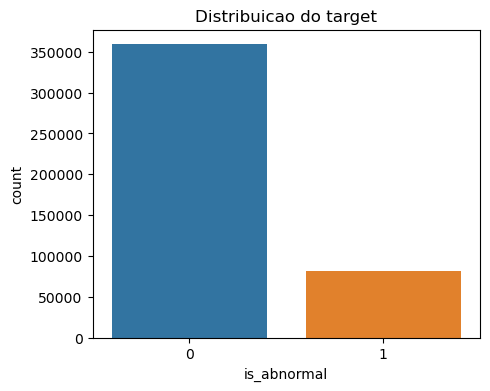

In [24]:
if "is_abnormal" not in df.columns:
    if "end_cause" not in df.columns:
        raise KeyError("Nao existe is_abnormal nem end_cause para definir o target.")
    NORMAL_END_CAUSES = {
        "Charging ends normally",
        "User stops charging",
    }
    df["is_abnormal"] = (~df["end_cause"].isin(NORMAL_END_CAUSES)).astype(int)

target_summary = df["is_abnormal"].value_counts().sort_index().rename_axis("is_abnormal").to_frame("sessions")
target_summary["percentage"] = target_summary["sessions"] / len(df) * 100
display(target_summary)
print(f"Razao maioritaria/minoritaria: {target_summary['sessions'].max() / target_summary['sessions'].min():.2f}")
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="is_abnormal")
plt.title("Distribuicao do target")
plt.show()


## 2. Variáíveis numéricas e relação com o target

Aqui comparamos as distribuições e os valores por classe, excluindo `userid` e `charging_post_id`, que são identificadores. Os outliers são observados, mas não são removidos.


is_abnormal                                    0          1
post_previous_sessions_1d      median  10.000000  11.000000
                               mean    10.595387  12.773781
post_previous_abnormal_1d      median   1.000000   3.000000
                               mean     1.515229   6.132509
post_previous_abnormal_rate_1d median   0.125000   0.263158
...                                          ...        ...
relative_humidity              mean    75.028267  75.039483
precipitation_mm               median   0.000000   0.000000
                               mean     3.484655   3.624853
electricity_price              median   0.901400   0.901400
                               mean     0.753873   0.743266

[64 rows x 2 columns]

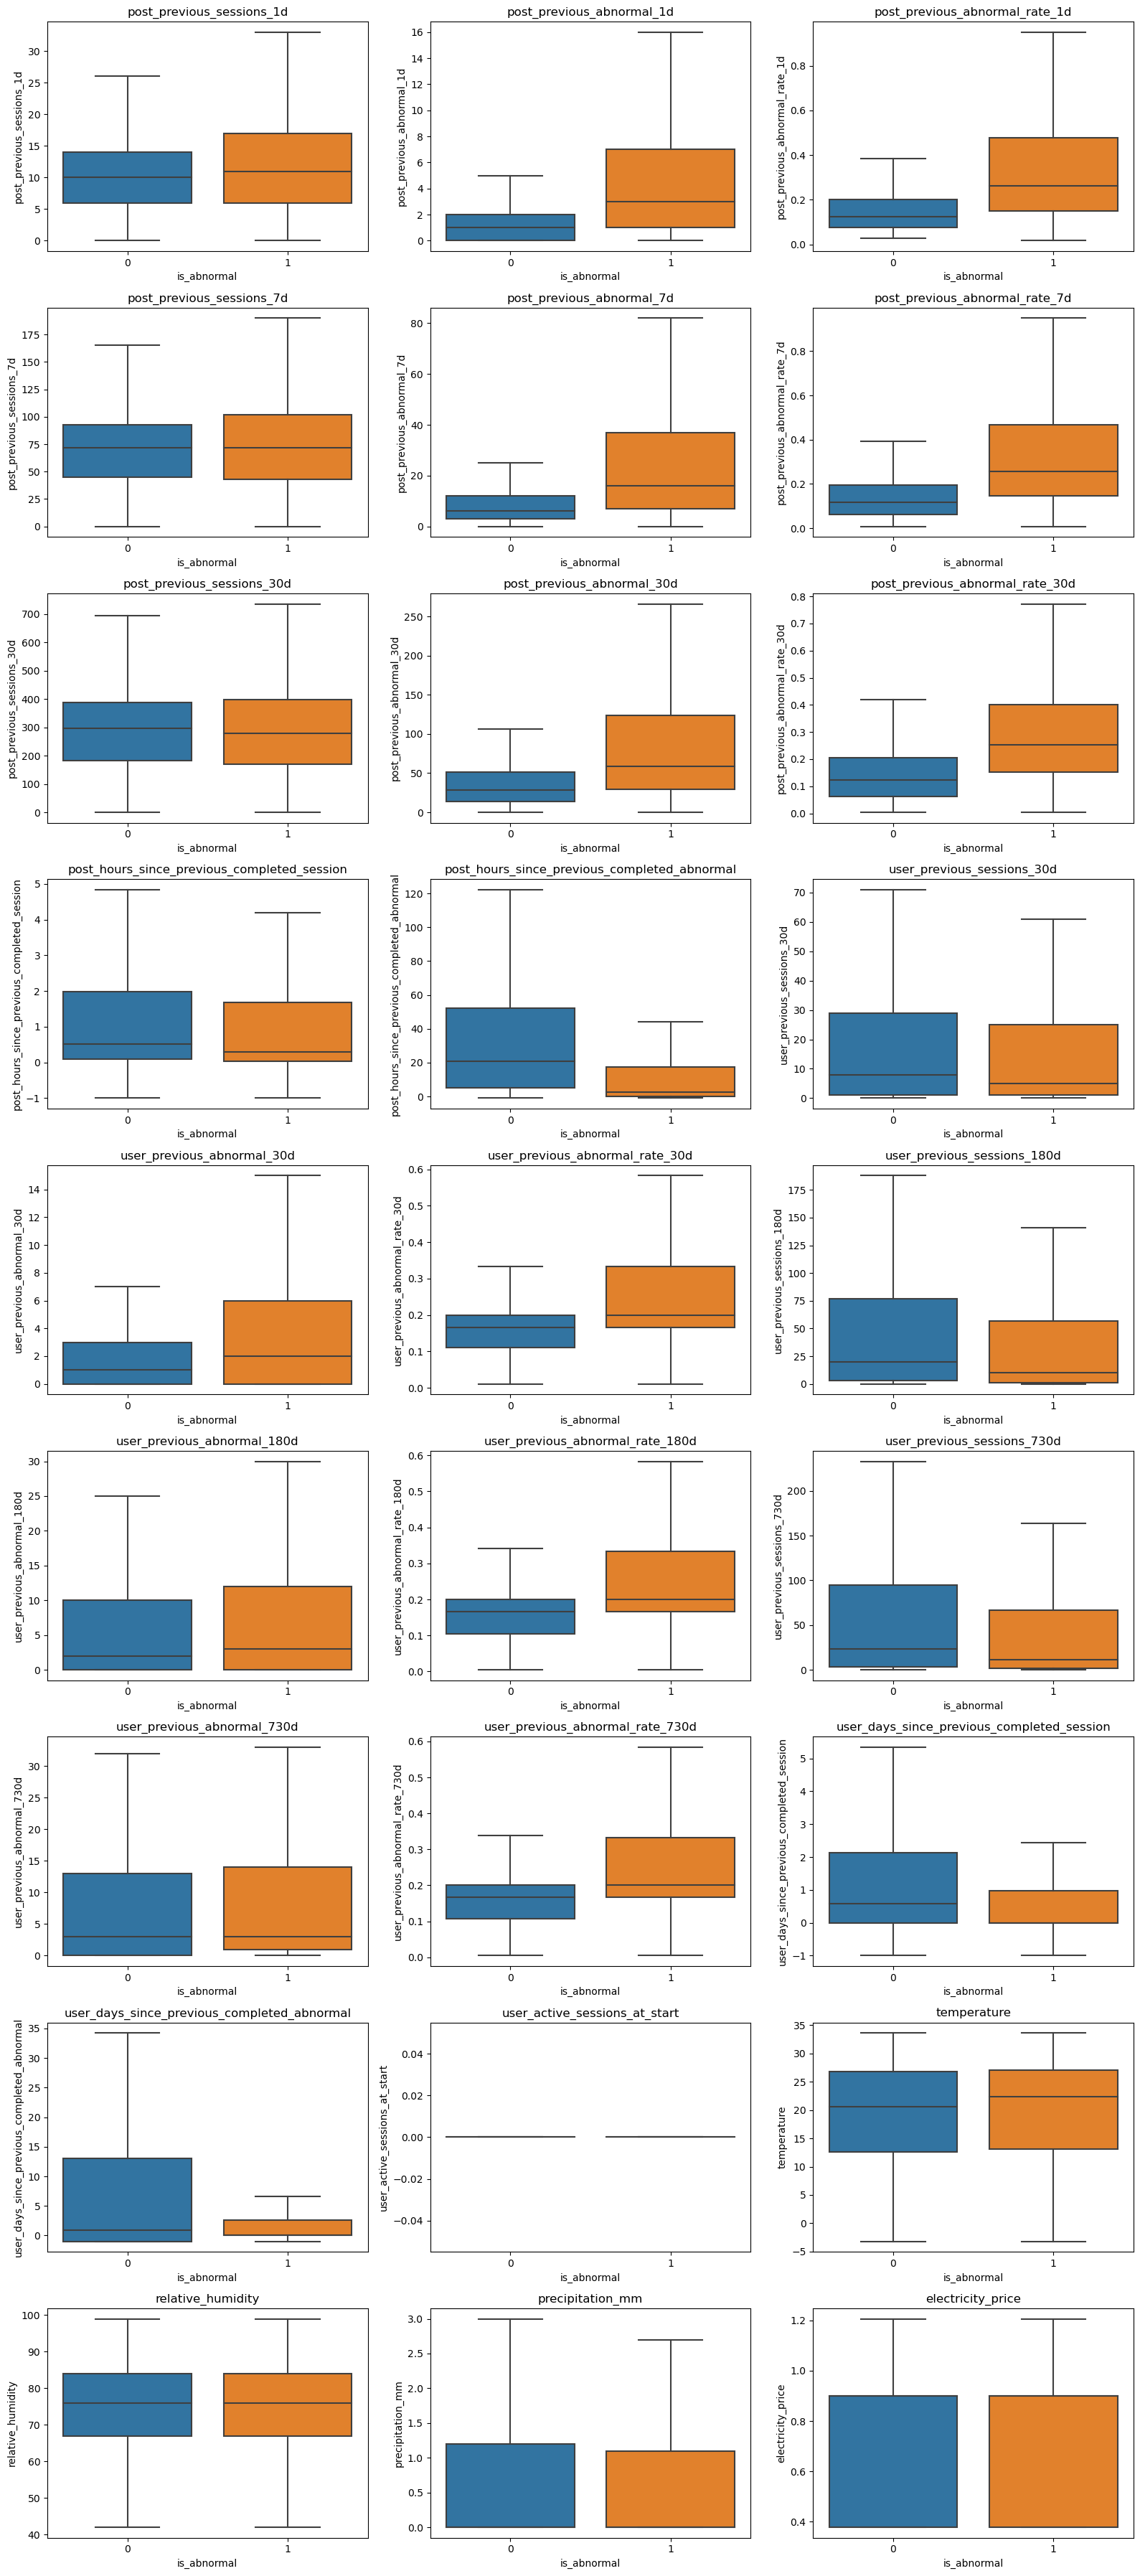

In [25]:
history_cols = [c for c in df.columns if c.startswith("post_") or c.startswith("user_")] + ["is_new_user"]
environment_cols = [c for c in ["temperature", "relative_humidity", "precipitation_mm", "electricity_price"] if c in df.columns]
eda_numeric = [c for c in history_cols + environment_cols if c in df.columns]
display(df.groupby("is_abnormal")[eda_numeric].agg(["median", "mean"]).T)
plot_cols = [c for c in eda_numeric if df[c].nunique(dropna=True) > 2]
fig, axes = plt.subplots(int(np.ceil(len(plot_cols) / 3)), 3, figsize=(16, 4 * int(np.ceil(len(plot_cols) / 3))))
axes = np.atleast_1d(axes).ravel()
for ax, col in zip(axes, plot_cols):
    sns.boxplot(data=df, x="is_abnormal", y=col, showfliers=False, ax=ax)
    ax.set_title(col)
for ax in axes[len(plot_cols):]:
    ax.remove()
plt.tight_layout()
plt.show()


Diferenças nas medianas, médias ou dispersões indicam variáveis com comportamentos diferentes entre as classes e que poderão ser relevantes. As distribuições assimétricas devem ser consideradas mais tarde. Estas diferenças representam associações e não demonstram causalidade.

## 3. Outliers nas variáveis numéricas
Os outliers são observações muito afastadas do intervalo habitual de uma variável. Nesta fase, são identificados através da regra do intervalo interquartil (IQR), mas não são eliminados nem substituídos. A análise ajuda a perceber se algumas variáveis têm valores extremos ou distribuições muito assimétricas.

,variable,lower_bound,upper_bound,outlier_count,outlier_percentage
30,precipitation_mm,-1.800000,3.000000,84609,19.182365
22,user_days_since_previous_completed_session,-2.970243,4.952442,70996,16.096056
24,user_days_since_previous_completed_abnormal,-18.745660,28.576100,63859,14.477971
23,user_no_previous_completed_session,0.000000,0.000000,56647,12.842882
17,user_previous_abnormal_180d,-15.000000,25.000000,56638,12.840842
20,user_previous_abnormal_730d,-19.500000,32.500000,56481,12.805247
27,is_new_user,0.000000,0.000000,56116,12.722495
9,post_hours_since_previous_completed_session,-2.729028,4.736528,55524,12.588278
19,user_previous_sessions_730d,-126.000000,218.000000,52719,11.952335
16,user_previous_sessions_180d,-104.500000,179.500000,49725,11.273542


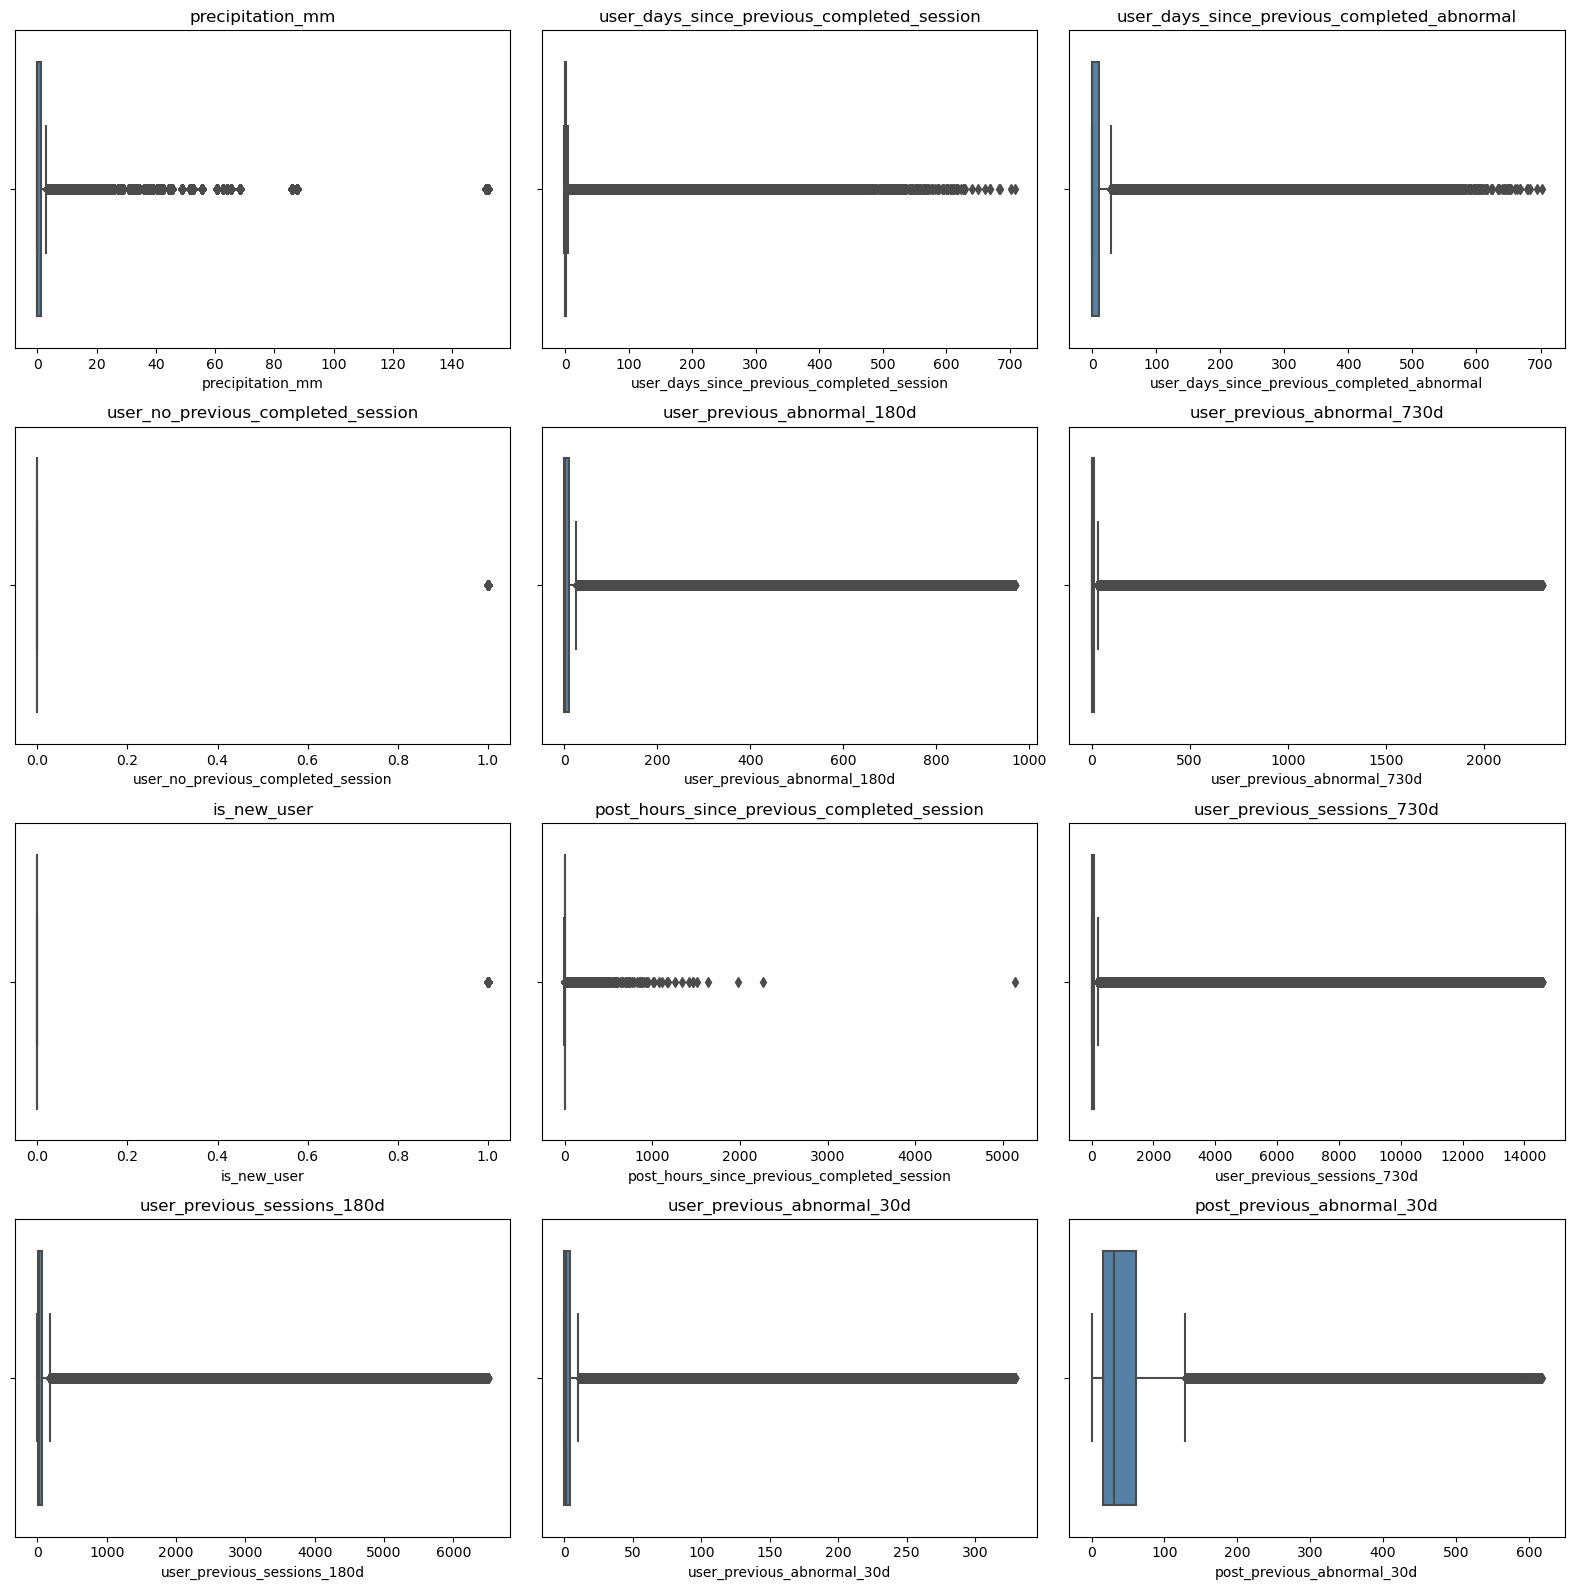

In [26]:
outlier_rows = []
for col in eda_numeric:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)
    outlier_rows.append({
        "variable": col,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": int(mask.sum()),
        "outlier_percentage": mask.mean() * 100
    })

outlier_summary = (pd.DataFrame(outlier_rows)
                   .sort_values("outlier_percentage", ascending=False))
display(outlier_summary)

outlier_plot_cols = outlier_summary.head(12)["variable"].tolist()
fig, axes = plt.subplots(int(np.ceil(len(outlier_plot_cols) / 3)), 3,
                         figsize=(16, 4 * int(np.ceil(len(outlier_plot_cols) / 3))))
axes = np.atleast_1d(axes).ravel()
for ax, col in zip(axes, outlier_plot_cols):
    sns.boxplot(x=df[col], ax=ax, color="steelblue")
    ax.set_title(col)
for ax in axes[len(outlier_plot_cols):]:
    ax.remove()
plt.tight_layout()
plt.show()

A tabela indica quais variáveis apresentam mais observações fora dos limites do IQR. Estes valores podem representar variabilidade real, distribuições assimétricas ou situações que devem ser investigadas. Não são considerados erros automaticamente e não são removidos nesta fase.

## 3. Variáveis categóricas
Nesta parte analisamos a relação de location_information, district_name e tariff_period com o target, mantendo as categorias raras e mostrando o número de sessões.

,sessions,abnormal_sessions,abnormal_rate
location_information,,,
Bus Station,60809,6104,10.037988
Park B,57294,4930,8.604740
Shopping Mall,56605,14453,25.533080
Expressway Service District C,50187,15256,30.398310
Government Agency,36551,4489,12.281470
Wholesale Market,34491,9153,26.537358
Technology Park,28867,2804,9.713514
Park A,27845,5644,20.269348
Tourist Attraction,23659,6215,26.269073


c:\Users\ritav\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 9 (	) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


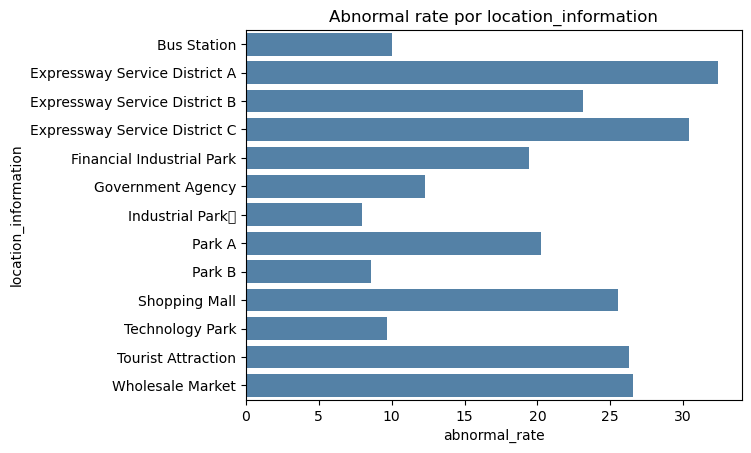

,sessions,abnormal_sessions,abnormal_rate
district_name,,,
Tongxiang,220923,32591,14.752199
Xiuzhou,148705,36652,24.647456
Nanhu,71449,12691,17.762320


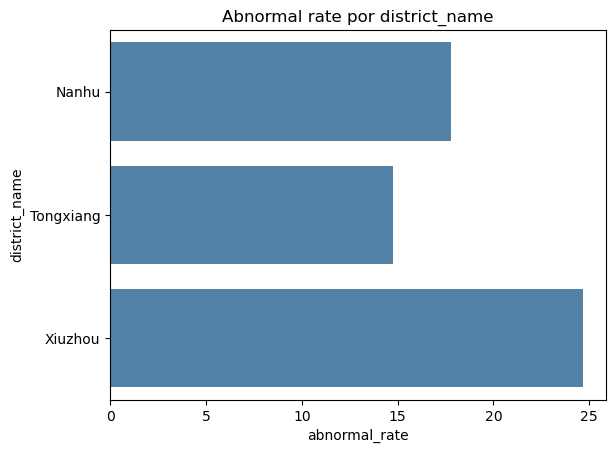

,sessions,abnormal_sessions,abnormal_rate
tariff_period,,,
peak_13_19,167118,31996,19.145753
off_peak_11_13,61760,12649,20.480894
peak_08_11,48977,8589,17.536803
off_peak_00_08,48633,8941,18.384636
sharp_19_21,48042,8043,16.741601
off_peak_22_24,43704,7874,18.016658
peak_21_22,22843,3842,16.819157


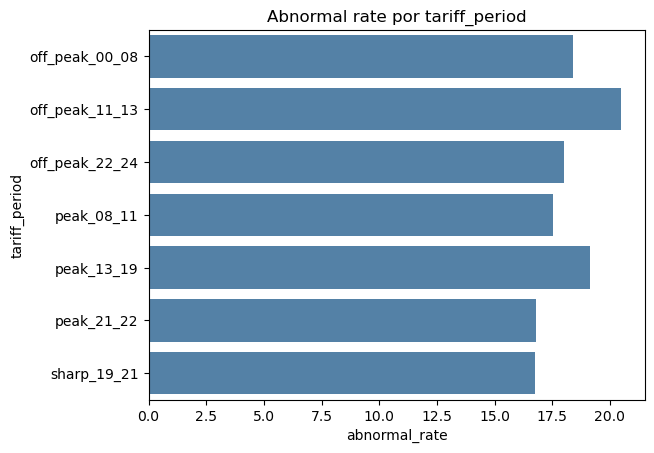

In [27]:
categorical_focus = [c for c in ["location_information", "district_name", "tariff_period"] if c in df.columns]
for col in categorical_focus:
    summary = df.groupby(col, dropna=False)["is_abnormal"].agg(sessions="size", abnormal_sessions="sum", abnormal_rate="mean")
    summary["abnormal_rate"] *= 100
    display(summary.sort_values("sessions", ascending=False))
    sns.barplot(data=summary.reset_index(), y=col, x="abnormal_rate", color="steelblue")
    plt.title(f"Abnormal rate por {col}")
    plt.show()


As categorias com abnormal rates diferentes apresentam uma associação observada com o target. As categorias com poucas sessões produzem estimativas menos estáveis. Não são eliminadas nem codificadas.

## 4. Relação entre as variáveis e o target
Comparamos os grupos de histórico do charging post e do utilizador. Estas variáveis representam informação disponível no início da sessão e podem revelar diferenças entre sessões normais e anormais.

In [28]:
feature_groups = {
    "Post history": [c for c in df.columns if c.startswith("post_")],
    "User history": [c for c in df.columns if c.startswith("user_")] + ["is_new_user"]
}
for group, cols in feature_groups.items():
    cols = [c for c in cols if c in df.columns]
    print(group)
    display(df.groupby("is_abnormal")[cols].mean().T)


Post history


is_abnormal,0,1
post_previous_sessions_1d,10.595387,12.773781
post_previous_abnormal_1d,1.515229,6.132509
post_previous_abnormal_rate_1d,0.157641,0.339057
post_previous_sessions_7d,70.029846,76.138904
post_previous_abnormal_7d,10.335284,29.455489
post_previous_abnormal_rate_7d,0.148154,0.336754
post_previous_sessions_30d,287.467922,292.562392
post_previous_abnormal_30d,44.554244,93.861523
post_previous_abnormal_rate_30d,0.155983,0.305385
post_hours_since_previous_completed_session,2.646801,3.012096


User history


is_abnormal,0,1
user_previous_sessions_30d,57.947500,45.947323
user_previous_abnormal_30d,8.520353,9.775917
user_previous_abnormal_rate_30d,0.175938,0.262134
user_previous_sessions_180d,192.811003,149.165951
user_previous_abnormal_180d,31.388029,28.738997
user_previous_abnormal_rate_180d,0.174127,0.256947
user_previous_sessions_730d,368.593215,285.541460
user_previous_abnormal_730d,58.908983,50.862499
user_previous_abnormal_rate_730d,0.174784,0.256307
user_days_since_previous_completed_session,7.247034,6.267852


Quando as médias ou medianas diferem entre as classes, o grupo apresenta comportamentos distintos e poderá ser relevante. Esta comparação não faz seleção de features nem permite afirmar causalidade.

## 5. District, Location e Charging Post
Analisamos a cardinalidade, as relações de pertença, o volume de sessões e a abnormal rate. Os charging posts com poucas observações exigem cautela.

In [29]:
for col in ["district_name", "location_information", "charging_post_id"]:
    print(col, df[col].nunique(dropna=False), "valores distintos")
display(df.groupby("district_name")["location_information"].nunique())
display(df.groupby("location_information")["charging_post_id"].nunique())
print("Post pertence a uma location:", df.groupby("charging_post_id")["location_information"].nunique().max() == 1)
print("Location pertence a um district:", df.groupby("location_information")["district_name"].nunique().max() == 1)
for col in ["district_name", "location_information", "charging_post_id"]:
    out = df.groupby(col)["is_abnormal"].agg(sessions="size", abnormal_rate="mean")
    out["abnormal_rate"] *= 100
    display(out.sort_values("sessions", ascending=False).head(20))


district_name 3 valores distintos
location_information 13 valores distintos
charging_post_id 92 valores distintos


district_name
Nanhu        3
Tongxiang    5
Xiuzhou      5
Name: location_information, dtype: int64

location_information
Bus Station                      8
Expressway Service District A    4
Expressway Service District B    4
Expressway Service District C    8
Financial Industrial Park        8
Government Agency                8
Industrial Park\t                8
Park A                           8
Park B                           8
Shopping Mall                    8
Technology Park                  4
Tourist Attraction               8
Wholesale Market                 8
Name: charging_post_id, dtype: int64

Post pertence a uma location: True
Location pertence a um district: True


,sessions,abnormal_rate
district_name,,
Tongxiang,220923,14.752199
Xiuzhou,148705,24.647456
Nanhu,71449,17.762320


,sessions,abnormal_rate
location_information,,
Bus Station,60809,10.037988
Park B,57294,8.604740
Shopping Mall,56605,25.533080
Expressway Service District C,50187,30.398310
Government Agency,36551,12.281470
Wholesale Market,34491,26.537358
Technology Park,28867,9.713514
Park A,27845,20.269348
Tourist Attraction,23659,26.269073


,sessions,abnormal_rate
charging_post_id,,
77,8728,28.242438
46,8097,5.384710
54,7990,26.645807
59,7858,9.035378
79,7854,34.288261
52,7842,5.024229
53,7659,5.431518
56,7626,9.179124
21,7619,31.053944


A consistência das pertencas mostra se existe uma hierarquia estável. Os volumes e as abnormal rates descrevem diferenças de utilização, mas não provam que uma location ou um charging post cause anomalias.

## 6. Preparação temporal
Criamos variáveis auxiliares para a EDA: ano, mês, semana, dia, dia da semana e hora.

In [30]:
for col in ["order_creation_time", "start_time"]:
    if not pd.api.types.is_datetime64_any_dtype(df[col]):
        df[col] = pd.to_datetime(df[col], errors="coerce")
session_time = df["start_time"].fillna(df["order_creation_time"])
df["eda_year"] = session_time.dt.year
df["eda_month"] = session_time.dt.to_period("M").astype(str)
df["eda_week"] = session_time.dt.to_period("W").astype(str)
df["eda_day"] = session_time.dt.date
df["eda_day_of_week"] = session_time.dt.day_name()
df["eda_hour"] = session_time.dt.hour
print(df[["order_creation_time", "start_time", "eda_month", "eda_day_of_week", "eda_hour"]].head())


  order_creation_time          start_time eda_month eda_day_of_week  eda_hour
0 2019-12-31 21:26:58 2019-12-31 21:27:03   2019-12         Tuesday        21
1 2019-12-31 21:50:58 2019-12-31 21:50:56   2019-12         Tuesday        21
2 2019-12-31 22:19:34 2019-12-31 22:12:46   2019-12         Tuesday        22
3 2019-12-31 22:37:24 2019-12-31 22:38:55   2019-12         Tuesday        22
4 2019-12-31 23:32:28 2019-12-31 23:06:44   2019-12         Tuesday        23


## 7. Volume de sessões ao longo do tempo
A contagem por mês e por semana identifica períodos de maior ou menor atividade, sazonalidade aparente ou alterações abruptas, sem inventar causas.

,sessions
eda_month,
2019-12,17
2020-01,6217
2020-02,1391
2020-03,6392
2020-04,11136
2020-05,15033
2020-06,17513
2020-07,22032
2020-08,25562


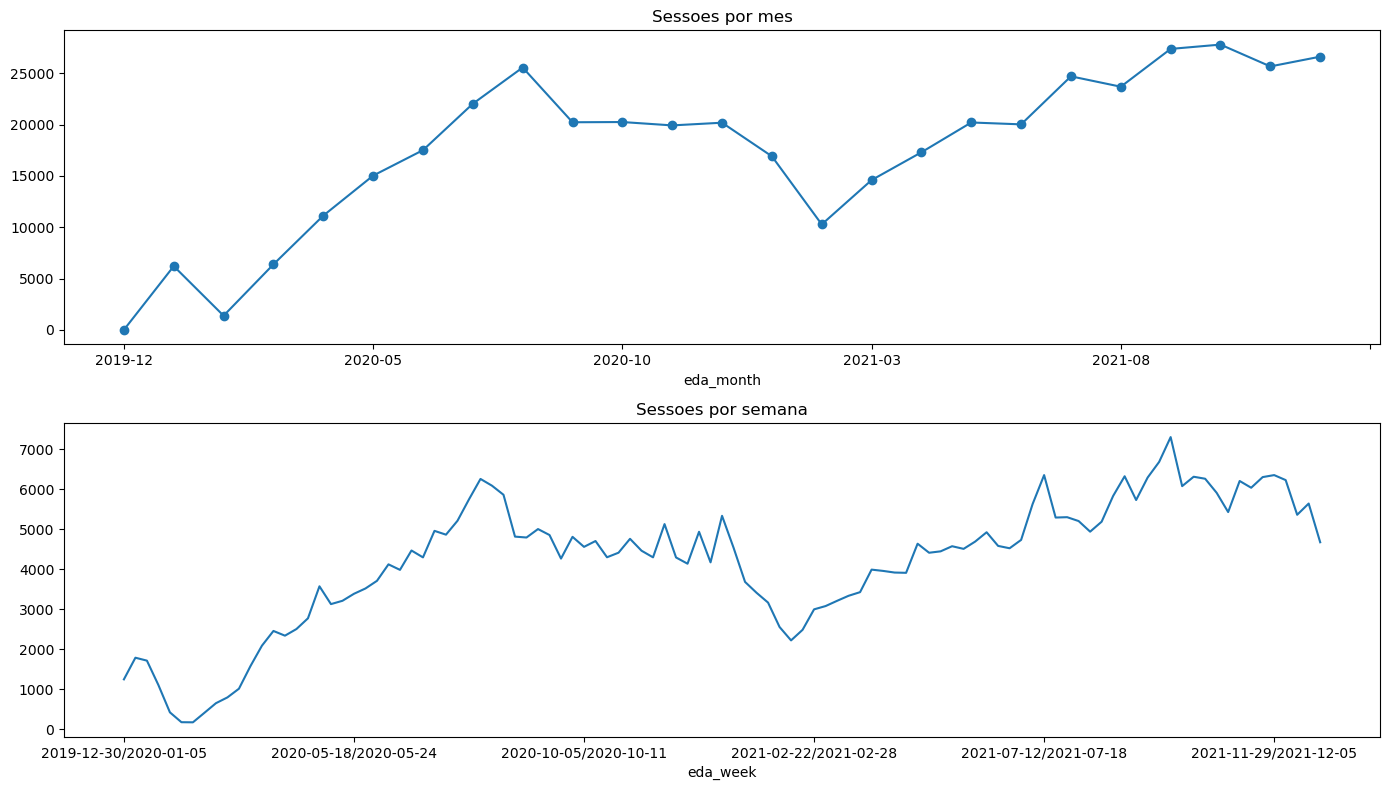

In [31]:
monthly_volume = df.groupby("eda_month").size().rename("sessions")
weekly_volume = df.groupby("eda_week").size().rename("sessions")
display(monthly_volume.to_frame())
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
monthly_volume.plot(ax=axes[0], marker="o", title="Sessoes por mes")
weekly_volume.plot(ax=axes[1], title="Sessoes por semana")
plt.tight_layout()
plt.show()


Os picos e vales representam alterações reais no volume observado. Os períodos com poucas sessões devem ser interpretados com cuidado e a variação não permite inferir a sua causa.

## 8. Abnormal rate ao longo do tempo
Calculamos mensalmente abnormal_rate = sessões anormais / sessões totais, mostrando também o volume total.

,sessions,abnormal_sessions,abnormal_rate
eda_month,,,
2019-12,17,5,29.411765
2020-01,6217,1555,25.012064
2020-02,1391,366,26.312006
2020-03,6392,1584,24.780976
2020-04,11136,2456,22.054598
2020-05,15033,2884,19.184461
2020-06,17513,2801,15.993833
2020-07,22032,4015,18.223493
2020-08,25562,5128,20.061028


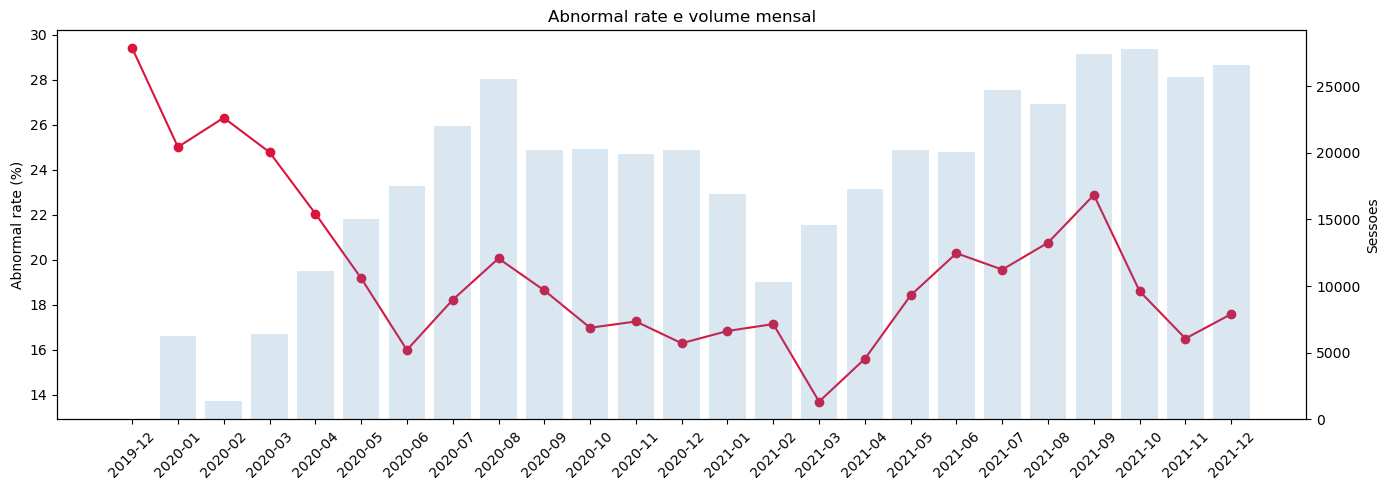

In [32]:
monthly_rate = df.groupby("eda_month")["is_abnormal"].agg(sessions="size", abnormal_sessions="sum", abnormal_rate="mean")
monthly_rate["abnormal_rate"] *= 100
display(monthly_rate)
fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(monthly_rate.index, monthly_rate["abnormal_rate"], marker="o", color="crimson")
ax1.set_ylabel("Abnormal rate (%)")
ax1.tick_params(axis="x", rotation=45)
ax2 = ax1.twinx()
ax2.bar(monthly_rate.index, monthly_rate["sessions"], alpha=.2, color="steelblue")
ax2.set_ylabel("Sessoes")
plt.title("Abnormal rate e volume mensal")
plt.tight_layout()
plt.show()


A estabilidade ou variação da abnormal rate deve ser avaliada juntamente com o volume. Pequenas diferenças em meses com poucas sessões não são evidência suficiente de temporal drift.

## 9. Análise por hora, dia da semana e mês
Agregamos as sessões, as sessões anormais e a abnormal rate por hora, dia da semana e mês. A ordem dos dias é fixada de Monday a Sunday.

,sessions,abnormal_sessions,abnormal_rate
eda_hour,,,
0,11381,2190,19.242597
1,7012,1352,19.281232
2,5101,1001,19.623603
3,4548,853,18.755497
4,3969,755,19.022424
5,3876,710,18.317853
6,5670,968,17.072310
7,7076,1112,15.715093
8,9746,1621,16.632465


,sessions,abnormal_sessions,abnormal_rate
eda_day_of_week,,,
Monday,62064,11303,18.211846
Tuesday,61465,11245,18.294965
Wednesday,62093,11607,18.692928
Thursday,63220,12117,19.166403
Friday,65562,12371,18.869162
Saturday,64463,11984,18.590509
Sunday,62210,11307,18.175534


,sessions,abnormal_sessions,abnormal_rate
eda_month,,,
2019-12,17,5,29.411765
2020-01,6217,1555,25.012064
2020-02,1391,366,26.312006
2020-03,6392,1584,24.780976
2020-04,11136,2456,22.054598
2020-05,15033,2884,19.184461
2020-06,17513,2801,15.993833
2020-07,22032,4015,18.223493
2020-08,25562,5128,20.061028


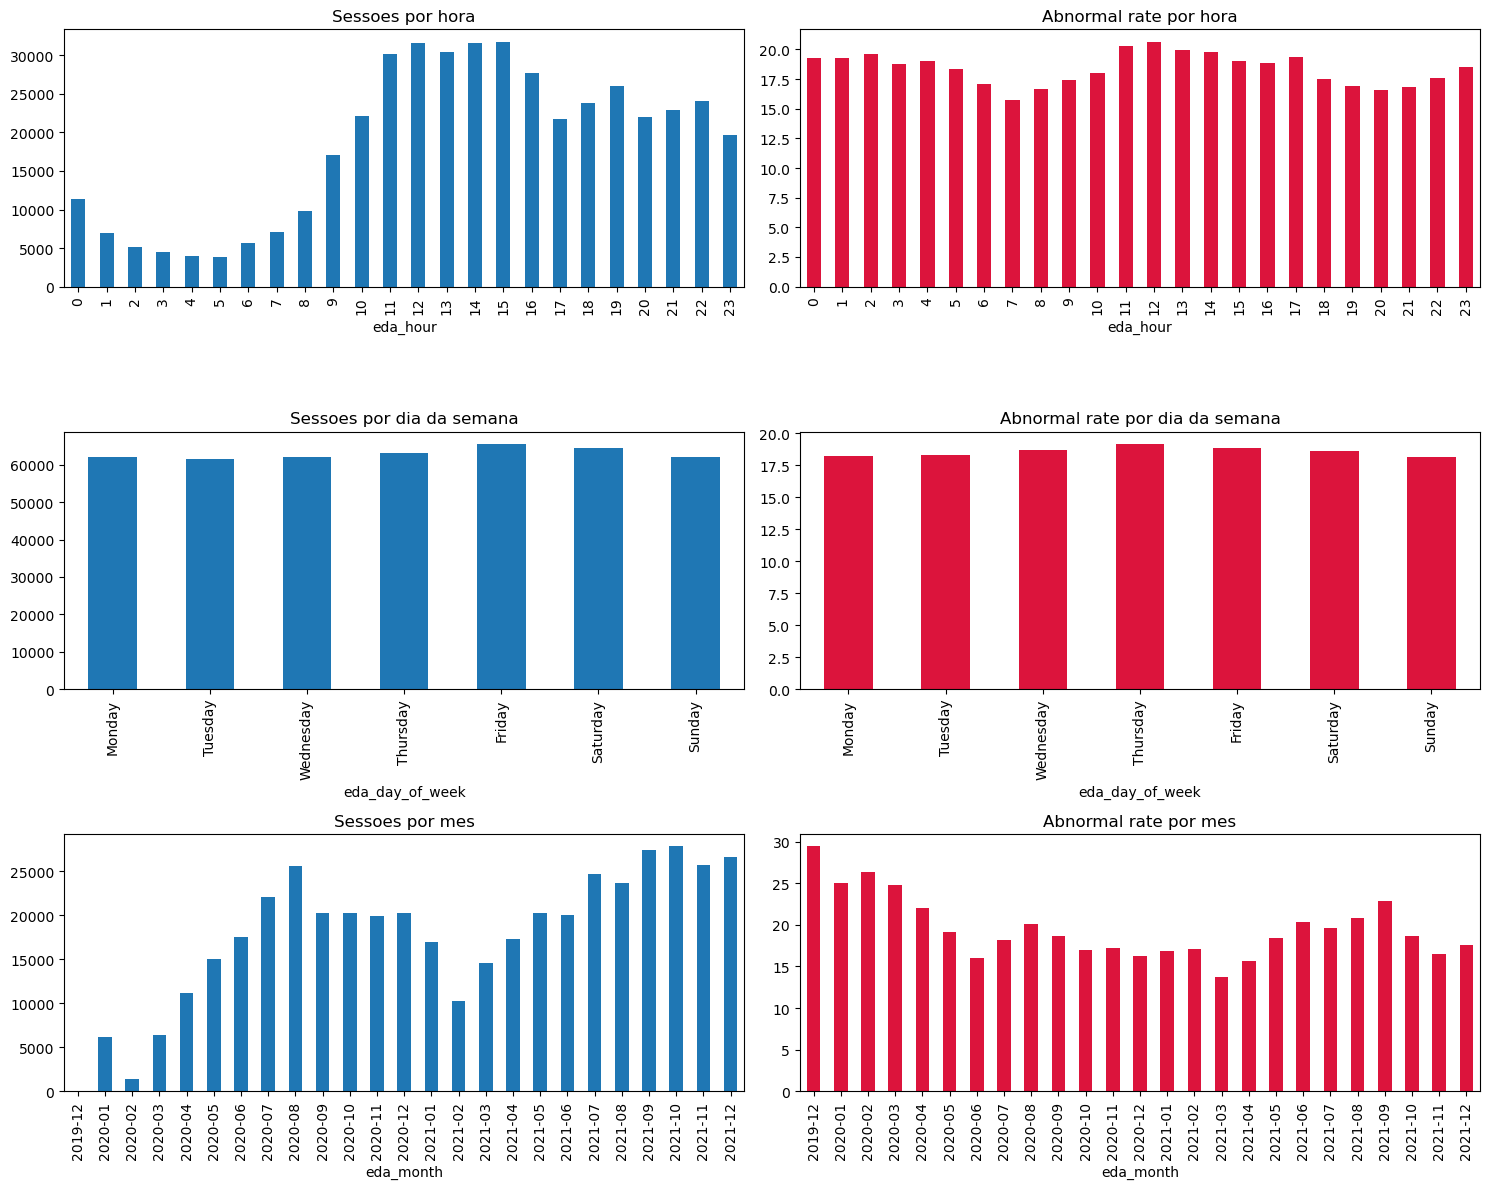

In [33]:
def temporal_summary(column):
    out = df.groupby(column)["is_abnormal"].agg(sessions="size", abnormal_sessions="sum", abnormal_rate="mean")
    out["abnormal_rate"] *= 100
    return out
hour_summary = temporal_summary("eda_hour")
day_summary = temporal_summary("eda_day_of_week").reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
month_summary = temporal_summary("eda_month")
display(hour_summary)
display(day_summary)
display(month_summary)
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
for row, summary, title in [(0, hour_summary, "hora"), (1, day_summary, "dia da semana"), (2, month_summary, "mes")]:
    summary["sessions"].plot(kind="bar", ax=axes[row, 0], title=f"Sessoes por {title}")
    summary["abnormal_rate"].plot(kind="bar", ax=axes[row, 1], color="crimson", title=f"Abnormal rate por {title}")
plt.tight_layout()
plt.show()


Os gráficos mostram os períodos com maior volume e as diferenças de abnormal rate. Qualquer padrão deve ser suportado pelo número de sessões; diferenças observacionais não demonstram causalidade.

## 10. Atividade dos utilizadores
Analisamos os utilizadores distintos por mês, as sessões por utilizador, is_new_user e user_active_sessions_at_start, para perceber se a população e a intensidade de utilização mudam.

,distinct_users
eda_month,
2019-12,16
2020-01,1963
2020-02,516
2020-03,1797
2020-04,2622
2020-05,3153
2020-06,3185
2020-07,3704
2020-08,4733


,sessions
count,56115.000000
mean,7.860233
std,74.159350
min,1.000000
25%,1.000000
50%,2.000000
75%,4.000000
max,14584.000000


,sessions,abnormal_rate
is_new_user,,
0,384961,0.182870
1,56116,0.205574


,sessions,abnormal_rate
user_active_sessions_at_start,,
0,420500,0.185054
1,11718,0.238351
2,3799,0.164517
3,2026,0.139684
4,1153,0.138768
5,728,0.135989
6,448,0.129464
7,304,0.125000
8,197,0.152284


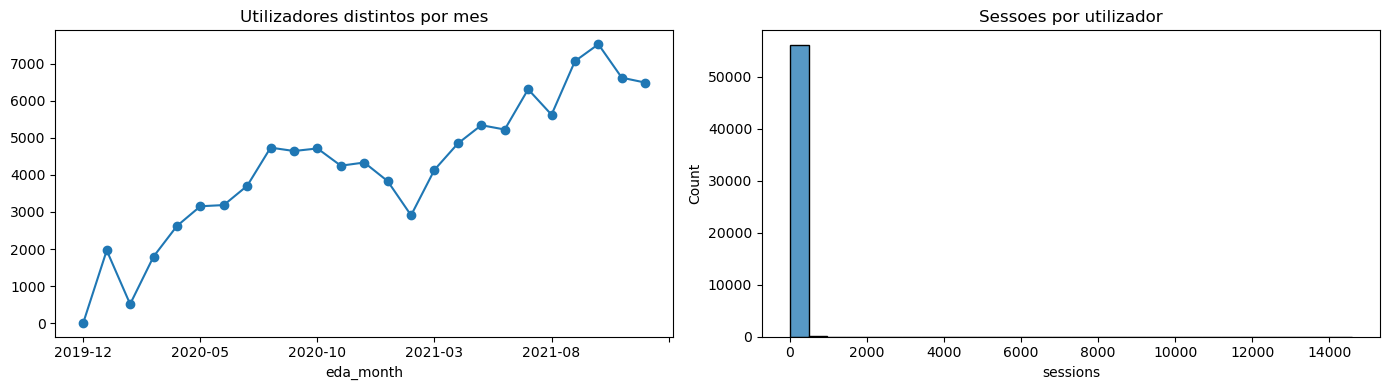

In [34]:
sessions_per_user = df.groupby("userid").size().rename("sessions")
users_by_month = df.groupby("eda_month")["userid"].nunique().rename("distinct_users")
display(users_by_month.to_frame())
display(sessions_per_user.describe().to_frame())
for col in ["is_new_user", "user_active_sessions_at_start"]:
    display(df.groupby(col)["is_abnormal"].agg(sessions="size", abnormal_rate="mean"))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
users_by_month.plot(ax=axes[0], marker="o", title="Utilizadores distintos por mes")
sns.histplot(sessions_per_user, bins=30, ax=axes[1])
axes[1].set_title("Sessoes por utilizador")
plt.tight_layout()
plt.show()


A evolução dos utilizadores distintos indica se a população observada muda. A distribuição de sessões mostra se a atividade está concentrada em poucos utilizadores. As relações com o target são descritivas.

## 11. Atividade dos charging posts
Analisamos os charging posts ativos por mês, as sessões por post e a abnormal rate por post. Os posts com poucas observações são mantidos, mas não sustentam conclusões fortes.

,active_posts
eda_month,
2019-12,17
2020-01,92
2020-02,83
2020-03,92
2020-04,92
2020-05,92
2020-06,91
2020-07,92
2020-08,92


,sessions
count,92.000000
mean,4794.315217
std,2157.846107
min,797.000000
25%,2957.500000
50%,4368.000000
75%,7064.750000
max,8728.000000


,sessions,abnormal_rate
charging_post_id,,
77,8728,28.242438
46,8097,5.384710
54,7990,26.645807
59,7858,9.035378
79,7854,34.288261
52,7842,5.024229
53,7659,5.431518
56,7626,9.179124
21,7619,31.053944


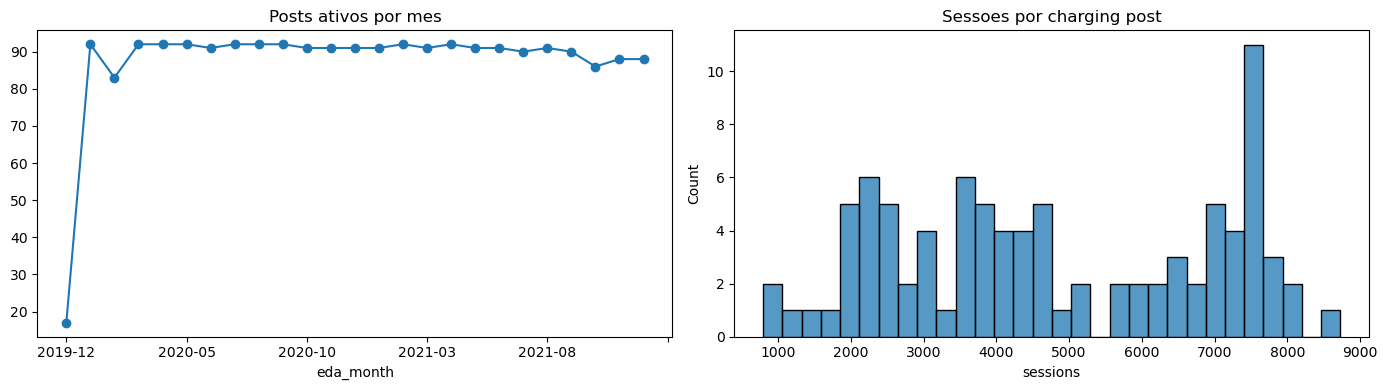

In [35]:
posts_by_month = df.groupby("eda_month")["charging_post_id"].nunique().rename("active_posts")
sessions_per_post = df.groupby("charging_post_id").size().rename("sessions")
post_summary = df.groupby("charging_post_id")["is_abnormal"].agg(sessions="size", abnormal_rate="mean")
post_summary["abnormal_rate"] *= 100
display(posts_by_month.to_frame())
display(sessions_per_post.describe().to_frame())
display(post_summary.sort_values("sessions", ascending=False).head(20))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
posts_by_month.plot(ax=axes[0], marker="o", title="Posts ativos por mes")
sns.histplot(sessions_per_post, bins=30, ax=axes[1])
axes[1].set_title("Sessoes por charging post")
plt.tight_layout()
plt.show()


A evolução dos charging posts ativos e a distribuição das sessões descrevem a utilização da infraestrutura. Uma abnormal rate elevada num post com poucas observações é incerta e não demonstra um efeito causal.

## 12. Análise de correlação
Calculamos uma matriz apenas para as variáveis numéricas de histórico e ambientais, excluindo identificadores e variáveis posteriores à sessão. Correlação não significa causalidade nem determina a remoção de variáveis.

,post_previous_sessions_1d,post_previous_abnormal_1d,post_previous_abnormal_rate_1d,post_previous_sessions_7d,post_previous_abnormal_7d,post_previous_abnormal_rate_7d,post_previous_sessions_30d,post_previous_abnormal_30d,post_previous_abnormal_rate_30d,post_hours_since_previous_completed_session,...,user_no_previous_completed_session,user_days_since_previous_completed_abnormal,user_no_previous_completed_abnormal,user_active_sessions_at_start,is_new_user,temperature,relative_humidity,precipitation_mm,electricity_price,is_abnormal
post_previous_sessions_1d,1.000000,0.646801,0.301353,0.788516,0.497633,0.185250,0.696470,0.445817,0.119599,-0.159744,...,-0.039252,-0.012372,-0.065078,-0.006109,-0.039164,0.114629,-0.064283,-0.003122,-0.007440,0.129746
post_previous_abnormal_1d,0.646801,1.000000,0.848843,0.419314,0.752062,0.631096,0.287843,0.583567,0.487521,-0.047800,...,0.024038,-0.048758,-0.030661,-0.011349,0.023319,0.094627,-0.015878,0.007691,-0.000473,0.374288
post_previous_abnormal_rate_1d,0.301353,0.848843,1.000000,0.147684,0.681995,0.777721,0.037576,0.527585,0.624617,0.004240,...,0.054219,-0.068111,-0.015262,-0.012689,0.053083,0.053442,0.006642,0.012918,-0.004274,0.445734
post_previous_sessions_7d,0.788516,0.419314,0.147684,1.000000,0.575638,0.156205,0.898664,0.522467,0.080130,-0.162563,...,-0.033724,-0.002121,-0.057242,-0.008538,-0.033535,0.132995,-0.056147,-0.000098,-0.002100,0.067794
post_previous_abnormal_7d,0.497633,0.752062,0.681995,0.575638,1.000000,0.806959,0.413540,0.801776,0.635334,-0.048083,...,0.056396,-0.051151,-0.001159,-0.013599,0.055455,0.118979,-0.006045,0.014954,0.001565,0.349289
post_previous_abnormal_rate_7d,0.185250,0.631096,0.777721,0.156205,0.806959,1.000000,0.037740,0.650322,0.824643,0.016531,...,0.087736,-0.073908,0.015945,-0.014088,0.086425,0.053684,0.016541,0.013985,-0.005387,0.429657
post_previous_sessions_30d,0.696470,0.287843,0.037576,0.898664,0.413540,0.037740,1.000000,0.536907,0.036775,-0.156609,...,-0.038670,0.009307,-0.056754,-0.014269,-0.038303,0.105865,-0.058821,0.003355,-0.002020,0.014292
post_previous_abnormal_30d,0.445817,0.583567,0.527585,0.522467,0.801776,0.650322,0.536907,1.000000,0.767154,-0.052113,...,0.080919,-0.054225,0.021588,-0.011676,0.079992,0.127122,0.001291,0.019651,0.000822,0.286230
post_previous_abnormal_rate_30d,0.119599,0.487521,0.624617,0.080130,0.635334,0.824643,0.036775,0.767154,1.000000,0.028360,...,0.113342,-0.080863,0.040485,-0.009858,0.111835,0.054569,0.026432,0.013766,-0.004675,0.368977
post_hours_since_previous_completed_session,-0.159744,-0.047800,0.004240,-0.162563,-0.048083,0.016531,-0.156609,-0.052113,0.028360,1.000000,...,0.030088,-0.000444,0.024000,-0.002139,0.029866,-0.040252,0.005343,-0.005362,-0.013007,0.008751


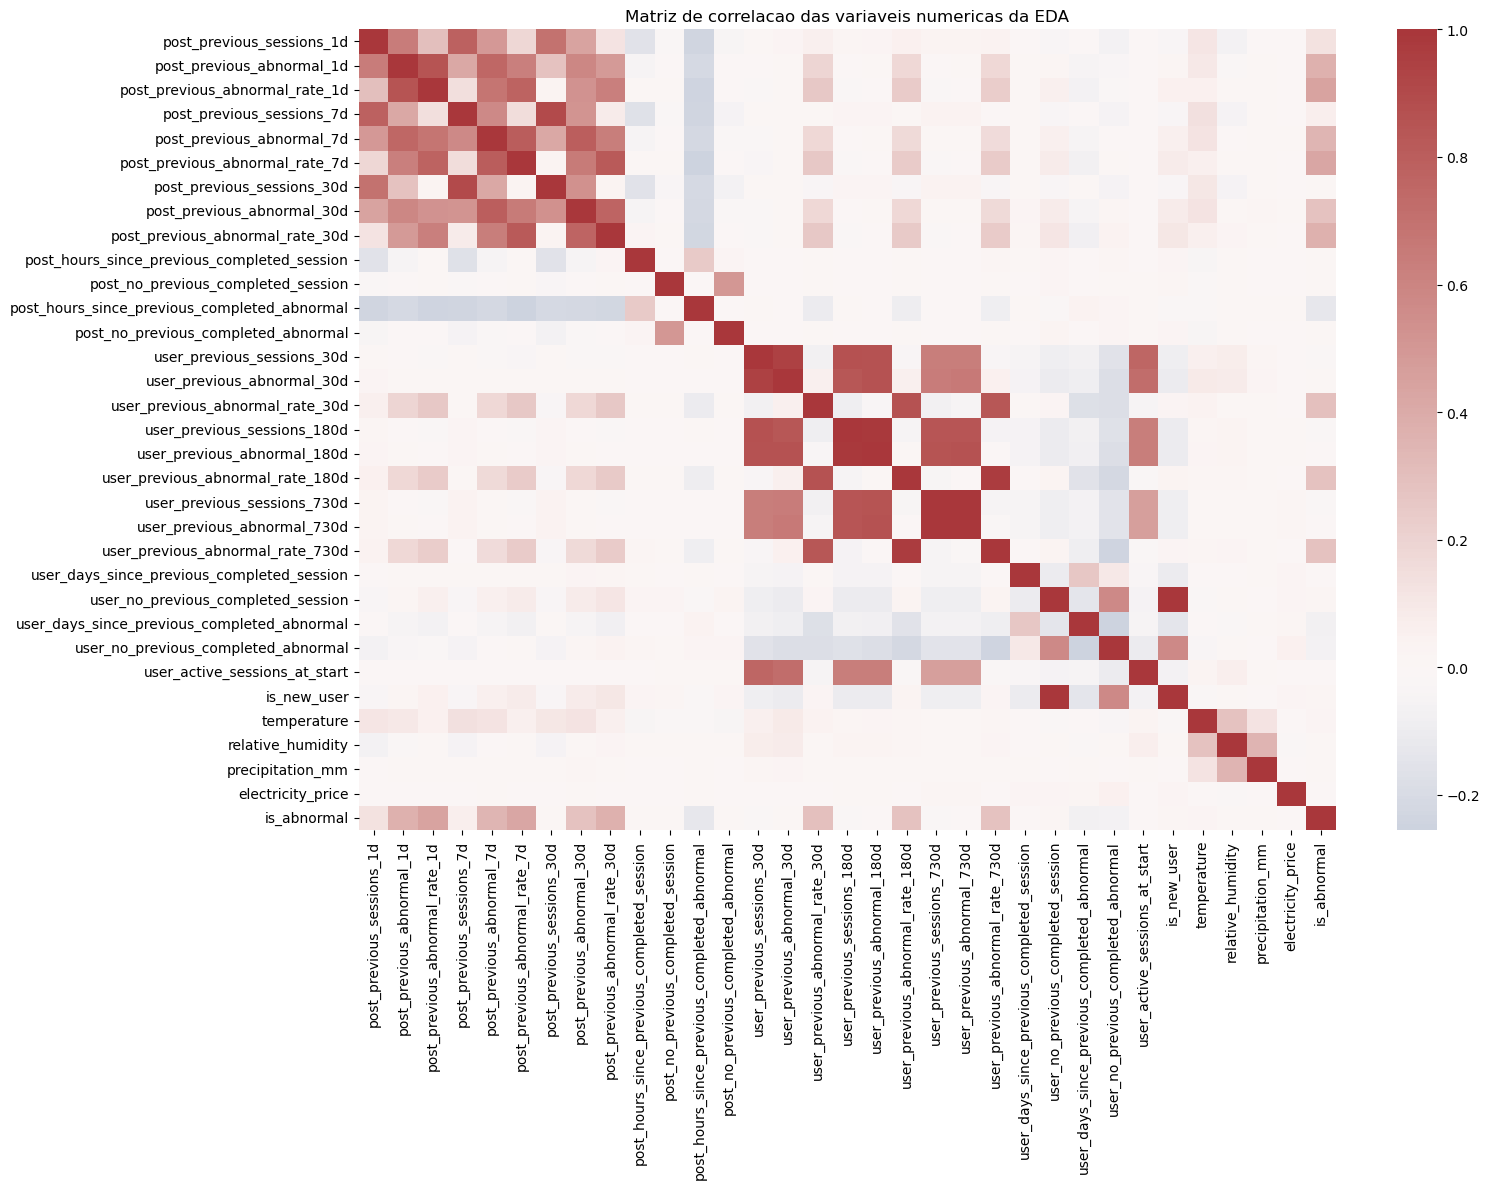

In [36]:
corr_cols = [c for c in eda_numeric + ["is_abnormal"] if c in df.columns]
corr_matrix = df[corr_cols].corr()
display(corr_matrix)
plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, cmap="vlag", center=0)
plt.title("Matriz de correlacao das variaveis numericas da EDA")
plt.tight_layout()
plt.show()


## 13. Temporal drift
Comparamos mensalmente o volume, a abnormal rate, as variáveis numéricas, os utilizadores, os charging posts e as categorias principais. O objetivo é decidir se o comportamento parece estável, se existem alterações temporais ou se a evidência é insuficiente.

In [37]:
drift_numeric = [c for c in ["temperature", "relative_humidity", "precipitation_mm", "electricity_price", "user_active_sessions_at_start"] if c in df.columns]
monthly_numeric = df.groupby("eda_month")[drift_numeric].median()
drift_table = monthly_rate[["sessions", "abnormal_rate"]].copy()
drift_table["distinct_users"] = users_by_month
drift_table["active_posts"] = posts_by_month
display(monthly_numeric)
display(drift_table)


,temperature,relative_humidity,precipitation_mm,electricity_price,user_active_sessions_at_start
eda_month,,,,,
2019-12,3.9,61.0,0.1,0.3784,0.0
2020-01,6.1,87.0,0.3,0.9014,0.0
2020-02,10.1,76.0,0.0,0.9014,0.0
2020-03,12.6,76.0,0.1,0.9014,0.0
2020-04,16.0,66.0,0.0,0.9014,0.0
2020-05,23.2,79.0,0.0,0.9014,0.0
2020-06,26.1,90.0,2.1,0.9014,0.0
2020-07,26.6,89.0,0.9,0.9014,0.0
2020-08,31.2,72.0,0.0,0.9014,0.0


,sessions,abnormal_rate,distinct_users,active_posts
eda_month,,,,
2019-12,17,29.411765,16,17
2020-01,6217,25.012064,1963,92
2020-02,1391,26.312006,516,83
2020-03,6392,24.780976,1797,92
2020-04,11136,22.054598,2622,92
2020-05,15033,19.184461,3153,92
2020-06,17513,15.993833,3185,91
2020-07,22032,18.223493,3704,92
2020-08,25562,20.061028,4733,92


# Leakage e Preparação de dados para modelação

## 1. Momento da previsão
O instante de previsão deve ser definido como imediatamente antes ou no momento de início da sessão, usando apenas informação conhecida até ao Start Time.

A variável end_cause só é conhecida depois do término da sessão. Portanto, todas as variáveis derivadas do resultado da sessão devem ser excluídas.

## 2. Variáveis disponíveis no início 

### Contexto
Estas variáveis podem ser utilizadas, desde que estejam disponíveis no momento de início:

- Charging Post ID
- Location Information
- District Name
- Temperature(℃)
- Relative Humidity(%)
- Precipitation(mm)
- electricity_price
- tariff_period
- hora, dia da semana, mês e feriado derivados de Start Time
- Order creation time também pode ser utilizado se o sistema o conhecer antes do início da sessão. Pode ser transformado em order_to_start_minutes = Start Time - Order creation time. Não deve ser usado como timestamp bruto.

### Sessão
Variáveis potencialmente disponíveis no início:

- UserID
- Charging Post ID
- Start Time
- Transaction power/kwh, apenas se for uma potência contratada/programada antes do início
- atributos de localização e tarifa

A interpretação de Transaction power/kwh deve ser confirmada. Se representar a energia efetivamente consumida durante a sessão, é leakage. Se representar um valor solicitado ou planeado antes do início, pode ser mantida.

### Histórico do charging post
As seguintes variáveis parecem explicitamente calculadas antes do início da sessão e devem ser mantidas:

- post_previous_sessions_1D
- post_previous_abnormal_1D
- post_previous_abnormal_rate_1D
- post_previous_sessions_7D
- post_previous_abnormal_7D
- post_previous_abnormal_rate_7D
- post_previous_sessions_30D
- post_previous_abnormal_30D
- post_previous_abnormal_rate_30D
- post_hours_since_previous_completed_session
- post_no_previous_completed_session
- post_hours_since_previous_completed_abnormal
- post_no_previous_completed_abnormal

Estas features são úteis para representar:

- carga recente do posto;
- taxa histórica de anomalias;
- existência de falhas recentes;
- tempo desde a última sessão ou falha.


### Histórico do utilizador
As seguintes variáveis também devem ser mantidas:

- is_new_user
- user_previous_sessions_30D
- user_previous_abnormal_30D
- user_previous_abnormal_rate_30D
- user_previous_sessions_180D
- user_previous_abnormal_180D
- user_previous_abnormal_rate_180D
- user_previous_sessions_730D
- user_previous_abnormal_730D
- user_previous_abnormal_rate_730D
- user_days_since_previous_completed_session
- user_no_previous_completed_session
- user_days_since_previous_completed_abnormal
- user_no_previous_completed_abnormal
- user_active_sessions_at_start (é especialmente importante para representar concorrência ou utilização simultânea do utilizador. Deve ser mantida se for realmente um snapshot calculado no instante de início)

## 3. Variáveis com data leakage 
Exclui-se qualquer variável que seja derivada do resultado da sessão, como:
| Variável                    | Motivo                                      |
|-----------------------------|---------------------------------------------|
| `end_cause`                 | É o próprio alvo                            |
| `End Time`                  | Só é conhecido depois da sessão terminar    |
| `Payment time`              | O pagamento ocorre depois ou perto do final |
| `Electricity cost/Yuan`     | Depende da energia consumida                |
| `Service charge/Yuan`       | É calculado para a sessão                   |
| `Transaction Amount/Yuan`   | Resultado financeiro da sessão              |
| `Actual Payment/Yuan`       | Só é conhecido depois do pagamento          |

Excluem-se também variáveis consoante a semântica, como:
| Variável                 | Motivo                                                                 |
|--------------------------|------------------------------------------------------------------------|
| `Transaction power/kwh`  | Excluir se for energia consumida; manter apenas se for valor contratado/programado |
| `Temperature(℃)`         | Manter se for medição no início; excluir se for média da sessão       |
| `Relative Humidity(%)`   | Manter se for medição no início; excluir se for média da sessão       |
| `Precipitation(mm)`      | Manter se for observado/previsionado no início; excluir se for acumulado até ao fim |

## 4. Conjunto final de variáveis recomendadas para modelação


### Features temporais
Derivadas de Start Time, estas variáveis representam o instante de início da sessão e podem ser utilizadas como features:
- start_hour
- start_day_of_week
- start_day_of_month
- start_month
- is_holiday (se existir informação sobre feriados, pode ser derivada de Start Time)
- is_weekend (derivada de start_day_of_week, indica se é fim de semana)

Para tariff_period, não é necessário criar novamente a hora se o período tarifário estiver correto, mas manter start_hour permite capturar padrões adicionais.

### Features de contexto
Estas variáveis representam o contexto da sessão e podem ser utilizadas como features:
- charging_post_id
- location_information
- district_name
- electricity_price
- tariff_period
- temperature
- relative_humidity
- precipitation

### Features de histórico do charging post
Estas variáveis representam o histórico do charging post e podem ser utilizadas como features:
- post_previous_sessions_1D
- post_previous_abnormal_1D
- post_previous_abnormal_rate_1D
- post_previous_sessions_7D
- post_previous_abnormal_7D
- post_previous_abnormal_rate_7D
- post_previous_sessions_30D
- post_previous_abnormal_30D
- post_previous_abnormal_rate_30D
- post_hours_since_previous_completed_session
- post_no_previous_completed_session
- post_hours_since_previous_completed_abnormal
- post_no_previous_completed_abnormal

### Features de histórico do utilizador
Estas variáveis representam o histórico do utilizador e podem ser utilizadas como features:
- is_new_user é parcialmente redundante com as contagens de sessões anteriores, mas pode ser mantida para representar explicitamente a ausência de histórico
- user_previous_sessions_30D
- user_previous_abnormal_30D
- user_previous_abnormal_rate_30D
- user_previous_sessions_180D
- user_previous_abnormal_180D
- user_previous_abnormal_rate_180D
- user_previous_sessions_730D
- user_previous_abnormal_730D
- user_previous_abnormal_rate_730D
- user_days_since_previous_completed_session
- user_no_previous_completed_session
- user_days_since_previous_completed_abnormal
- user_no_previous_completed_abnormal
- user_active_sessions_at_start


## 5. IDs e Risco de memória

Utilizar `userid` e `charging_post_id` como features pode introduzir **risco de memória** no modelo, uma vez que estes identificadores podem ser únicos ou quase únicos para cada sessão. Isto significa que o modelo pode aprender padrões específicos para cada ID, em vez de generalizar para novos utilizadores ou postos de carregamento.

Opções para lidar com UserId:

- Modelo principal: não utilizar o UserID bruto; usar apenas histórico do utilizador.
- Modelo de comparação: usar encoding de frequência calculado apenas no treino.
- Target encoding: apenas dentro de cada fold temporal, nunca calculado no dataset completo.
- Recomendação: excluir o UserID bruto do primeiro modelo.

Recomendação para Charging Post ID:

- manter Charging Post ID como categórica para modelos de árvore;
- para modelos lineares, usar one-hot apenas se o número de postos for moderado;
- comparar com uma versão sem o ID;
- usar frequency encoding calculado exclusivamente no treino se houver muitos postos.

## 6. Importância das features
A importância das features deve ser avaliada com base em métricas de desempenho do modelo.

Treinar pelo menos estes modelos com o mesmo split temporal:

| Modelo | Features |
|--------|----------|
| A | Contexto + sessão |
| B | A + histórico do charging post |
| C | A + histórico do utilizador |
| D | A + histórico do posto + histórico do utilizador |

Comparar:
- macro F1 score,
- balanced accuracy;
- F1 da classe charging_fault;
- recall das falhas;
- PR-AUC para a classificação binária;
- calibração das probabilidades.

A diferença de desempenho entre os modelos ajuda a perceber a importância relativa das features de contexto, histórico do posto e histórico do utilizador.
 - valor do histórivo do posto = desempenho do modelo B - desempenho do modelo A
 - valor do histórico do utilizador = desempenho do modelo C - desempenho do modelo A
 - valor combinado = desempenho do modelo D - desempenho do modelo A

## 7. Estratégia de pré-processamento

A estratégia de pré-processamento é fundamental para garantir a qualidade dos dados antes de aplicar qualquer técnica de análise ou modelagem. Ela envolve várias etapas que ajudam a preparar os dados para a análise, como limpeza, transformação e normalização.

Numéricas, categóricas e temporais são tratadas de forma diferente, com técnicas específicas para cada tipo de variável. A escolha das técnicas de pré-processamento deve ser baseada na natureza dos dados e nos objetivos da análise ou modelagem.

#### Numéricas
Não substituir automaticamente valores em falta por zero, porque missing e zero têm significados diferentes.

Para as variáveis históricas, os indicadores post_no_previous_* e user_no_previous_* devem ser aproveitados como informação explícita de ausência de histórico (-1).

#### Categóricas
- Location Information: one-hot encoding;
- District Name: one-hot encoding;
- tariff_period: one-hot encoding;
- Charging Post ID: one-hot ou frequency encoding, dependendo da cardinalidade;
- UserID: preferencialmente excluir do primeiro modelo ou aplicar encoding controlado.

Utilizar handle_unknown = "ignore", para categorias novas no validation/test.

#### Target encoding
Se for utilizado para postos ou utilizadores:
- calcular estatísticas apenas no treino;
- em teste, usar apenas o mapa aprendido no treino;
- nunca calcular target encoding antes do split.

## 8. Class imbalance e métricas de avaliação
O dataset apresenta um **desbalanceamento de classes**, com a classe `charging_fault` representando apenas 3,5% das sessões. Este desbalanceamento pode afetar o desempenho do modelo, tornando-o tendencioso para a classe majoritária.

Para lidar com este desbalanceamento, recomenda-se:
- começar com class_weights ou balanced loss functions;
- avaliar métricas como macro-F1 e balanced accuracy, não apenas accuracy;
- monitorizar recall das falhas;
- utilizar matriz de confusão normalizada;
- evitar ovesampling aleatório antes do split temporal, para não introduzir leakage.

SMOTE não deve ser aplicado diretamente sem cuidado, porque pode misturar períodos temporais, pode criar sessões sintéticas sem significado físico e pode usar implicitamente informação de validação se aplicado antes do split.

Se o desempenho for insuficiente:
- agrupar causas extremamente raras numa classe other_fault ou utilizar um modelo hierárquico: normal/user stop vs fault -tipo de falha apenas para as sessões classificadas como fault.

## 9. Split temporal
O split temporal é essencial para evitar **data leakage** e garantir que o modelo é avaliado em dados que representam o futuro em relação ao treino.

Deve ser realizado por Start Time, garantindo que todas as sessões de um mesmo utilizador ou charging post estão no mesmo conjunto (treino, validação ou teste). Isso evita que o modelo aprenda padrões específicos de um utilizador ou posto e os utilize para prever sessões futuras.

Recomenda-se dividir os dados em três conjuntos:
- Treino: 70% das sessões mais antigas;
- Teste: 30% das sessões mais recentes.

Alternativamente, utilizar datas fixas depois de inspeccionar o intervalo temporal.

O processo deve ser:
1. Ordenar o dataset por Start Time;
2. Dividir em treino, validação e teste com base nas proporções ou datas definidas;
3. Ajustar imputação, normalização e codificação apenas com os dados de treino;
4. Avaliar decisões de modelagem com os dados de validação;
5. Usar o conjunto de teste apenas para avaliação final do modelo.

Para seleção de hiperparâmetros, usar validação temporal expansiva:
Fold 1: treino inicial -> validação seguinte
Fold 2: treino maior   -> validação seguinte
Fold 3: treino maior   -> validação seguinte

Como as features históricas incluem janelas até 730 dias, pode ser usado um gap temporal entre treino e teste se as features forem recalculadas a partir de dados brutos.

## 10. Conclusão

A abordagem proposta para o problema de classificação de falhas em sessões de carregamento de veículos elétricos considera cuidadosamente os aspectos mais importantes da gestão de dados temporais, incluindo a divisão adequada dos dados, o tratamento de variáveis históricas e a aplicação de técnicas apropriadas para lidar com o desbalanceamento de classes. A implementação do pipeline completo, com validação temporal e seleção de hiperparâmetros, visa garantir que o modelo final seja robusto e generalizável.

O pipeline de pré-processamento e modelagem deve ser cuidadosamente projetado para evitar data leakage, garantir a integridade temporal dos dados e permitir uma avaliação justa do desempenho do modelo. A análise exploratória detalhada e a preparação dos dados são etapas cruciais para o sucesso do projeto, fornecendo insights valiosos sobre a natureza dos dados e as relações entre as variáveis.

O conjunto final de variáveis recomendadas para modelação inclui:
- features de contexto (informação do posto, localização, tarifa, condições ambientais);
- features de sessão (duração, potência, horário, etc.);
- features históricas (informação sobre o histórico do utilizador, posto, etc.).

Exclui-se variáveis que representam resultados da sessão ou que possam introduzir data leakage, garantindo que o modelo aprende apenas com informações disponíveis no momento do início da sessão. Tal como:
- end_cause
- end_time
- payment_time
- electricity_cost
- service_charge
- transaction_amount
- actual_payment
- transaction_power (se representar energia consumida)

In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def normalizar_variaveis_elegiveis(dataframe):
    """Normaliza variaveis elegiveis e imprime uma amostra do resultado."""
    numeric_columns = [
        "temperature", "relative_humidity", "precipitation_mm", "electricity_price",
        "post_previous_sessions_1d", "post_previous_abnormal_1d",
        "post_previous_abnormal_rate_1d", "post_previous_sessions_7d",
        "post_previous_abnormal_7d", "post_previous_abnormal_rate_7d",
        "post_previous_sessions_30d", "post_previous_abnormal_30d",
        "post_previous_abnormal_rate_30d", "post_hours_since_previous_completed_session",
        "post_hours_since_previous_completed_abnormal", "user_previous_sessions_30d",
        "user_previous_abnormal_30d", "user_previous_abnormal_rate_30d",
        "user_previous_sessions_180d", "user_previous_abnormal_180d",
        "user_previous_abnormal_rate_180d", "user_previous_sessions_730d",
        "user_previous_abnormal_730d", "user_previous_abnormal_rate_730d",
        "user_days_since_previous_completed_session",
        "user_days_since_previous_completed_abnormal", "user_active_sessions_at_start",
    ]
    binary_columns = [
        "is_new_user", "post_no_previous_completed_session",
        "post_no_previous_completed_abnormal", "user_no_previous_completed_session",
        "user_no_previous_completed_abnormal",
    ]
    categorical_columns = ["location_information", "district_name", "tariff_period"]
    eligible_columns = numeric_columns + binary_columns + categorical_columns
    available_columns = [c for c in eligible_columns if c in dataframe.columns]
    missing_columns = sorted(set(eligible_columns) - set(available_columns))
    if missing_columns:
        print("Colunas elegiveis ausentes:", missing_columns)

    numeric_columns = [c for c in numeric_columns if c in available_columns]
    binary_columns = [c for c in binary_columns if c in available_columns]
    categorical_columns = [c for c in categorical_columns if c in available_columns]
    transformers = []
    if numeric_columns:
        transformers.append(("numericas", StandardScaler(), numeric_columns))
    if categorical_columns:
        transformers.append((
            "categoricas", OneHotEncoder(handle_unknown="ignore", sparse=False), categorical_columns
        ))
    transformer = ColumnTransformer(
        transformers=transformers,
        remainder="passthrough",
        verbose_feature_names_out=False,
    )
    transformed = transformer.fit_transform(dataframe[available_columns])
    normalized_dataframe = pd.DataFrame(
        transformed,
        columns=transformer.get_feature_names_out(),
        index=dataframe.index,
    )
    print("Colunas numericas normalizadas:", numeric_columns)
    print("Colunas categoricas codificadas:", categorical_columns)
    print("Colunas binarias mantidas como 0/1:", binary_columns)
    print(f"Dimensoes antes: {dataframe.shape[0]:,} linhas x {len(available_columns)} colunas")
    print(f"Dimensoes depois: {normalized_dataframe.shape[0]:,} linhas x {normalized_dataframe.shape[1]} colunas")
    print("Amostra dos dados normalizados:")
    display(normalized_dataframe.head())
    return normalized_dataframe, transformer

normalized_df, normalization_transformer = normalizar_variaveis_elegiveis(df)

categorical_encoded_columns = [
    column
    for column in normalized_df.columns
    if column.startswith((
        "location_information_", "district_name_", "tariff_period_"
    ))
]
print("Colunas categoricas depois do one-hot encoding:")
print(categorical_encoded_columns)
print("Valores codificados das variaveis categoricas:")
display(normalized_df[categorical_encoded_columns].head())

c:\Users\ritav\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:972: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


Colunas numericas normalizadas: ['temperature', 'relative_humidity', 'precipitation_mm', 'electricity_price', 'post_previous_sessions_1d', 'post_previous_abnormal_1d', 'post_previous_abnormal_rate_1d', 'post_previous_sessions_7d', 'post_previous_abnormal_7d', 'post_previous_abnormal_rate_7d', 'post_previous_sessions_30d', 'post_previous_abnormal_30d', 'post_previous_abnormal_rate_30d', 'post_hours_since_previous_completed_session', 'post_hours_since_previous_completed_abnormal', 'user_previous_sessions_30d', 'user_previous_abnormal_30d', 'user_previous_abnormal_rate_30d', 'user_previous_sessions_180d', 'user_previous_abnormal_180d', 'user_previous_abnormal_rate_180d', 'user_previous_sessions_730d', 'user_previous_abnormal_730d', 'user_previous_abnormal_rate_730d', 'user_days_since_previous_completed_session', 'user_days_since_previous_completed_abnormal', 'user_active_sessions_at_start']
Colunas categoricas codificadas: ['location_information', 'district_name', 'tariff_period']
Colunas

,temperature,relative_humidity,precipitation_mm,electricity_price,post_previous_sessions_1d,post_previous_abnormal_1d,post_previous_abnormal_rate_1d,post_previous_sessions_7d,post_previous_abnormal_7d,post_previous_abnormal_rate_7d,...,tariff_period_off_peak_22_24,tariff_period_peak_08_11,tariff_period_peak_13_19,tariff_period_peak_21_22,tariff_period_sharp_19_21,is_new_user,post_no_previous_completed_session,post_no_previous_completed_abnormal,user_no_previous_completed_session,user_no_previous_completed_abnormal
0,-1.863763,-1.108581,-0.314837,0.517841,-1.684617,-0.494599,0.054706,-2.030614,-0.652305,0.098478,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0
1,-1.887343,-1.029568,-0.314837,0.517841,-1.684617,-0.494599,0.054706,-2.030614,-0.652305,0.098478,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0
2,-1.863763,-1.108581,-0.314837,-1.293765,-1.684617,-0.494599,0.054706,-2.030614,-0.652305,0.098478,...,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0
3,-1.863763,-1.108581,-0.314837,-1.293765,-1.684617,-0.494599,0.054706,-2.030614,-0.652305,0.098478,...,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0
4,-1.863763,-1.108581,-0.314837,-1.293765,-1.684617,-0.494599,0.054706,-2.030614,-0.652305,0.098478,...,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0


KeyError: 'location_information'